<div style="background:#0B1F3A;padding:22px 26px;border-radius:10px;color:white">
<div style="font-size:13px;letter-spacing:1px;opacity:.8">ENSIA · THE NATIONAL SCHOOL OF ARTIFICIAL INTELLIGENCE · INTELLIGENT SYSTEMS ENGINEERING DEPARTMENT</div>
<div style="font-size:15px;margin-top:4px;opacity:.9">4th Year, Semester 1 · Wireless Communication Networks and Systems · Academic year 2026–2027</div>
<h1 style="color:white;margin:14px 0 4px 0">Automatic Modulation Classification Using Deep Learning</h1>
<div style="font-size:15px;color:#F28C28">Semester Project · Dataset: RadioML RML2016.10a</div>
</div>





## Project question
> How can deep learning (DL) methods automatically identify the modulation scheme of a received wireless signal in modern 5G and 6G communication systems, and how does their classification performance change with the signal-to-noise ratio (SNR) and the dataset used?

## Objectives
Automatic Modulation Classification (AMC) identifies the modulation format of a received signal **without any prior knowledge or signalling from the transmitter**. It is a building block of cognitive radio, dynamic spectrum access, spectrum monitoring and interference identification. In this project we will:

1. **Understand and verify the data** — load RML2016.10a, inspect its organisation and report its exact specifications.
2. **Connect signals to physics** — visualise I/Q signals in the time, constellation and frequency domains and explain the effect of noise (SNR).
3. **Build a leakage-free pipeline** — label encoding, stratified 70/15/15 split, normalisation estimated on the training set only, fixed seeds.
4. **Establish a baseline** — implement the reference **VT-CNN2** model and evaluate it (accuracy vs SNR, F1, confusion matrices, cost).
5. **Go further** — implement advanced architectures (CNN-LSTM/CLDNN, ResNet-1D, Transformer, or 2D-CNN on images) and compare them with the baseline (t-SNE, complexity).
6. **Communicate honestly** — a scientific report and an oral defense that interpret the results from both a signal-processing and a machine-learning point of view.

> **This is not a race for the best accuracy**: method, reproducibility and interpretation matter most.

## Notebook roadmap
| Part | Content | 
|---|---|
| **0** | Setup: packages, imports, global configuration | 
| **A** | Task 1 — Dataset exploration (source, environment, loading, verification, description, questions) |
| **B** | Task 2 — Signal visualization and analysis |
| **C** | Task 3 — Data preparation and VT-CNN2 baseline |
| **D** | Tasks 4–5 — Advanced architectures, final evaluation |

---
# Part 0 — Setup, imports and global configuration

### 0.1 Install the required packages (run once)
Recommended: **Python 3.10 or 3.11**. The first line installs everything needed for Tasks 1–2 and the evaluation tools. TensorFlow is only needed from Task 3 onwards 

In [1]:
%pip install -q numpy scipy pandas matplotlib seaborn scikit-learn jinja2 tqdm
%pip install -q tensorflow      

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### 0.2 Imports for the entire project
All libraries used in the whole project are imported once here (data handling, signal processing, visualisation, evaluation, deep learning). TensorFlow is imported inside a `try` block so that Tasks 1–2 still run on a machine without it.

In [2]:
# ---------- Standard library ----------
import os, sys, io, json, time, math, random, pickle, tarfile, hashlib, platform, warnings
from pathlib import Path
from datetime import datetime
from collections import Counter

# ---------- Numerical computing and data handling ----------
import numpy as np
import pandas as pd
import scipy
from scipy import signal as sp_signal            # STFT / spectrograms / windows (Tasks 2 and 4)
from scipy.fft import fft, fftshift, fftfreq     # frequency-domain analysis (Task 2)

# ---------- Visualisation ----------
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
from IPython.display import display, Markdown, HTML

# ---------- Machine-learning utilities and evaluation ----------
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.manifold import TSNE                # latent-space visualisation (Task 4)

# ---------- Deep learning (TensorFlow / Keras) ----------
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, models, callbacks, optimizers, initializers
    HAS_TF = True
except ImportError:
    tf = keras = None
    HAS_TF = False
    print("ℹ️  TensorFlow is not installed: fine for Tasks 1-2, install it before Task 3.")

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

warnings.filterwarnings("ignore", category=FutureWarning)
print("Imports done ✔")

Imports done ✔


### 0.3 Global configuration, reproducibility and helper functions

In [3]:
# ---------- Reproducibility ----------
SEED = 42
random.seed(SEED); np.random.seed(SEED)
if HAS_TF:
    tf.keras.utils.set_random_seed(SEED)

# ---------- Paths ----------
DATA_DIR = Path("data")          # folder that already contains the dataset
FIG_DIR  = Path("figures")       # saved figures
PKL_NAME = "RML2016.10a_dict.pkl"
FIG_DIR.mkdir(exist_ok=True)

# ---------- Plot style ----------
TEAL, ORANGE, NAVY = "#0E8A9B", "#F28C28", "#0B1F3A"
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ---------- Helpers ----------
def human_size(n):
    for unit in ("B", "KB", "MB", "GB", "TB"):
        if n < 1024 or unit == "TB":
            return f"{n:.0f} {unit}" if unit == "B" else f"{n:.2f} {unit}"
        n /= 1024

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

def show(df, caption=None, fmt=None, cmap=None, hide_index=False):
    """Display a DataFrame as a nicely styled table."""
    sty = df.style
    if caption: sty = sty.set_caption(caption)
    if fmt:
        if isinstance(fmt, str):      # apply a single format only to numeric columns
            num_cols = df.select_dtypes("number").columns.tolist()
            sty = sty.format(fmt, subset=num_cols) if num_cols else sty
        else:
            sty = sty.format(fmt)
    if cmap:    sty = sty.background_gradient(cmap=cmap, axis=None)
    sty = sty.set_table_styles([
        {"selector": "caption", "props": [("font-size", "15px"), ("font-weight", "bold"),
                                           ("text-align", "left"), ("padding-bottom", "8px"), ("color", "white")]},
        {"selector": "thead th", "props": [("background-color", TEAL), ("color", "white"), ("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}])
    if hide_index: sty = sty.hide(axis="index")
    display(sty)

def banner(text, color=TEAL):
    display(HTML(f'<div style="background:{color};color:white;padding:8px 14px;border-radius:6px;'
                 f'font-weight:bold;font-size:15px;margin:10px 0 4px 0">{text}</div>'))

def color_status(v):
    if str(v).startswith("✅"): return "background-color:#d4edda;color:#155724;font-weight:bold"
    if str(v).startswith("❌"): return "background-color:#f8d7da;color:#721c24;font-weight:bold"
    return ""

print(f"Seed = {SEED} | data folder = {DATA_DIR.resolve()}")

Seed = 42 | data folder = C:\Users\WINDOWS\Desktop\wireless project\data


---
# Part A — Task 1: Dataset Exploration
**Objective:** locate the dataset (already stored in `data/`, nothing is downloaded) and understand its organisation.

| # | Required work | Section |
|---|---|---|
| 1 | Document the source of RML2016.10a and locate the local copy | A.1 – A.2 |
| 2 | Set up a Python environment and install the required packages | A.3 |
| 3 | Load the Pickle file using suitable Python libraries | A.4 – A.6 |
| 4 | Identify all modulation classes and SNR values | A.7 |
| 5 | Determine the number of observations and the shape of each observation | A.8 – A.9 |
| 6 | Examine class balance and the distribution of examples across SNR values | A.10 |
| 7 | Prepare a dataset description and summary table | A.11 – A.12 |
| Q | Answer the four questions + short exploratory analysis | A.13 – A.14 |

** ** 
** **
> 1. *the file name, format, and exact file size;*
> 2. *the available modulation labels and SNR values;*
> 3. *the number of examples per modulation and SNR;*
> 4. *the shape and data type of the signal arrays.*

## A.1 Locate the dataset files
The dataset is already in the `data/` folder. If only the `.tar.bz2` archive is present, it is extracted (nothing is downloaded).

In [4]:
def find_pickle(folder):
    for root, _, files in os.walk(folder):
        if PKL_NAME in files:
            return Path(root) / PKL_NAME
    return None

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Folder '{DATA_DIR}' not found. Current directory: {Path.cwd()}")

archives     = sorted(DATA_DIR.glob("*.bz2")) + sorted(DATA_DIR.glob("*.tar"))
ARCHIVE_PATH = archives[0] if archives else None
PKL_PATH     = find_pickle(DATA_DIR)

if PKL_PATH is None and ARCHIVE_PATH is not None:
    print("Extracting", ARCHIVE_PATH.name, "...")
    with tarfile.open(ARCHIVE_PATH, "r:*") as tar:
        tar.extractall(DATA_DIR)
    PKL_PATH = find_pickle(DATA_DIR)

if PKL_PATH is None:
    raise FileNotFoundError(f"'{PKL_NAME}' not found in '{DATA_DIR}'. Put the dataset there and re-run.")

listing = pd.DataFrame([{"File": str(p.relative_to(DATA_DIR)), "Size": human_size(p.stat().st_size)}
                        for p in sorted(DATA_DIR.rglob("*")) if p.is_file()])
show(listing, f"Content of the '{DATA_DIR}/' folder", hide_index=True)
print("✔ Dataset file used:", PKL_PATH)

File,Size
LICENSE.TXT,20.50 KB
RML2016.10a.tar.bz2,217.91 MB
RML2016.10a_dict.pkl,611.23 MB


✔ Dataset file used: data\RML2016.10a_dict.pkl


## A.2 Documented source of the dataset

In [5]:
source = pd.DataFrame({"Value": [
    "RadioML RML2016.10a (a.k.a. RML2016.10a_dict.pkl)",
    "DeepSig Inc. (T. J. O'Shea and N. West)",
    "https://www.deepsig.ai/datasets",
    "http://opendata.deepsig.io/datasets/2016.10/RML2016.10a.tar.bz2",
    "Synthetic, generated with GNU Radio; 11 modulations (8 digital + 3 analog); first released at the 6th GNU Radio Conference (2016)",
    "Creative Commons Attribution-NonCommercial-ShareAlike 4.0 (CC BY-NC-SA 4.0)",
    "Email-verified form on the DeepSig page (original access method)",
    f"✅ present in '{DATA_DIR}/' ({human_size(PKL_PATH.stat().st_size)})"]},
    index=["Dataset", "Author / owner", "Official page", "Direct file", "Description", "License", "Access method", "Local copy"])
show(source.reset_index().rename(columns={"index": "Item"}), "Documented source of the dataset", hide_index=True)

Item,Value
Dataset,RadioML RML2016.10a (a.k.a. RML2016.10a_dict.pkl)
Author / owner,DeepSig Inc. (T. J. O'Shea and N. West)
Official page,https://www.deepsig.ai/datasets
Direct file,http://opendata.deepsig.io/datasets/2016.10/RML2016.10a.tar.bz2
Description,"Synthetic, generated with GNU Radio; 11 modulations (8 digital + 3 analog); first released at the 6th GNU Radio Conference (2016)"
License,Creative Commons Attribution-NonCommercial-ShareAlike 4.0 (CC BY-NC-SA 4.0)
Access method,Email-verified form on the DeepSig page (original access method)
Local copy,✅ present in 'data/' (611.23 MB)


## A.3 Python environment and required packages

In [6]:
pkgs = [("numpy", np), ("scipy", scipy), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns),
        ("scikit-learn", sklearn)]
if HAS_TF: pkgs.append(("tensorflow", tf))
env_rows = [{"Package": "Python", "Version": sys.version.split()[0], "Purpose": f"interpreter ({platform.system()} {platform.release()})"}]
purpose = {"numpy": "arrays, I/Q manipulation", "scipy": "FFT, STFT, windows", "pandas": "tables",
           "matplotlib": "plots", "seaborn": "statistical plots", "scikit-learn": "split, metrics, t-SNE",
           "tensorflow": "deep learning (Keras)"}
for name, mod in pkgs:
    env_rows.append({"Package": name, "Version": mod.__version__, "Purpose": purpose[name]})
if HAS_TF:
    gpus = tf.config.list_physical_devices("GPU")
    env_rows.append({"Package": "GPU", "Version": f"{len(gpus)} device(s)", "Purpose": ", ".join(g.name for g in gpus) or "CPU only"})
show(pd.DataFrame(env_rows), "Environment", hide_index=True)


Package,Version,Purpose
Python,3.12.9,interpreter (Windows 11)
numpy,2.3.3,"arrays, I/Q manipulation"
scipy,1.17.0,"FFT, STFT, windows"
pandas,2.3.3,tables
matplotlib,3.10.6,plots
seaborn,0.13.2,statistical plots
scikit-learn,1.7.2,"split, metrics, t-SNE"
tensorflow,2.21.0,deep learning (Keras)
GPU,0 device(s),CPU only


## A.4 File name, format and exact file size

In [7]:
def pickle_protocol(path):
    with open(path, "rb") as f:
        head = f.read(2)
    return head[1] if head[:1] == b"\x80" else 0

rows = {}
files_to_check = [("Extracted data file", PKL_PATH)] + ([("Original archive", ARCHIVE_PATH)] if ARCHIVE_PATH else [])
for role, p in files_to_check:
    size = p.stat().st_size
    fmt  = (f"Python pickle (protocol {pickle_protocol(p)}, written by Python 2)"
            if p.suffix == ".pkl" else "tar archive compressed with bzip2 (.tar.bz2)")
    rows[p.name] = {"Role": role, "Format": fmt, "Exact size (bytes)": f"{size:,}",
                    "Size (human)": human_size(size), "SHA-256": sha256(p),
                    "Last modified": datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M")}
file_report = pd.DataFrame(rows).T
file_report.index.name = "File name"
show(file_report.reset_index(), "File verification report", hide_index=True)

File name,Role,Format,Exact size (bytes),Size (human),SHA-256,Last modified
RML2016.10a_dict.pkl,Extracted data file,"Python pickle (protocol 0, written by Python 2)","640,919,653",611.23 MB,b29ccc25b00d0718cd3b70ffa9158662ec83f6d9b63ffd845c7bcbe3b3096e8c,2018-06-26 19:17
RML2016.10a.tar.bz2,Original archive,tar archive compressed with bzip2 (.tar.bz2),"228,491,318",217.91 MB,7a1603dd61e557f45b6e113dc0c59be02a14509b77856c31bbb324a993f7974c,2026-11-20 12:33


## A.5 Load the pickle
The file was created with Python 2, so it must be opened with `encoding="latin1"`.

In [8]:
t0 = time.time()
with open(PKL_PATH, "rb") as f:
    Xd = pickle.load(f, encoding="latin1")
load_time = time.time() - t0

k0 = next(iter(Xd))
loaded = pd.DataFrame({"Value": [type(Xd).__name__, f"{len(Xd)}", f"(modulation: {type(k0[0]).__name__}, SNR: {type(k0[1]).__name__})  e.g. {k0}",
                                 type(Xd[k0]).__name__, f"{load_time:.1f} s"]},
                      index=["Python object", "Number of keys", "Key structure", "Value type", "Loading time"])
show(loaded.reset_index().rename(columns={"index": "Item"}), "Pickle content", hide_index=True)

Item,Value
Python object,dict
Number of keys,220
Key structure,"(modulation: str, SNR: int) e.g. ('QPSK', 2)"
Value type,ndarray
Loading time,5.9 s


## A.6 Data-loading function
The function below flattens the raw dictionary into the arrays used later for the stratified split: `X` of shape `(N, 2, 128)`, integer labels `y` and the SNR of every example.

In [9]:
def load_rml2016a(path):
    """
    Load RML2016.10a and flatten it.

    Returns
    -------
    X        : float32 array (N, 2, 128)  -- channel 0 = I, channel 1 = Q
    y        : int array (N,)             -- class index (alphabetical modulation order)
    snr      : int array (N,)             -- SNR in dB of every example
    mods     : list[str]                  -- modulation names, index = class id
    snrs     : list[int]                  -- sorted SNR values
    label2id : dict[str, int]             -- mapping to keep for training/testing/confusion matrices
    """
    with open(path, "rb") as f:
        d = pickle.load(f, encoding="latin1")      # file written with Python 2
    mods = sorted({k[0] for k in d})
    snrs = sorted({k[1] for k in d})
    label2id = {m: i for i, m in enumerate(mods)}
    X   = np.vstack([d[(m, s)] for m in mods for s in snrs]).astype(np.float32)
    y   = np.concatenate([np.full(d[(m, s)].shape[0], label2id[m]) for m in mods for s in snrs])
    snr = np.concatenate([np.full(d[(m, s)].shape[0], s) for m in mods for s in snrs])
    return X, y, snr, mods, snrs, label2id

In [10]:
X, y, snr, mods, snrs, label2id = load_rml2016a(PKL_PATH)
id2label = {i: m for m, i in label2id.items()}

show(pd.DataFrame({"Array": ["X", "y", "snr"],
                   "Shape": [X.shape, y.shape, snr.shape],
                   "dtype": [X.dtype, y.dtype, snr.dtype],
                   "Meaning": ["I/Q frames (channel 0 = I, channel 1 = Q)", "class index 0–10", "SNR in dB of each frame"]}),
     "Output of load_rml2016a()", hide_index=True)

Array,Shape,dtype,Meaning
X,"(220000, 2, 128)",float32,"I/Q frames (channel 0 = I, channel 1 = Q)"
y,"(220000,)",int64,class index 0–10
snr,"(220000,)",int64,SNR in dB of each frame


## A.7 Modulation classes and SNR values
The class index follows the **alphabetical order** of the modulation names. This mapping (`label2id`, returned by `load_rml2016a()`) must be reused unchanged for training, testing and confusion matrices (Task 3-B).

In [11]:
MOD_INFO = {   # modulation -> (family, type)
    "8PSK": ("PSK", "Digital"), "BPSK": ("PSK", "Digital"), "QPSK": ("PSK", "Digital"),
    "QAM16": ("QAM", "Digital"), "QAM64": ("QAM", "Digital"), "PAM4": ("PAM", "Digital"),
    "CPFSK": ("FSK", "Digital"), "GFSK": ("FSK", "Digital"),
    "AM-DSB": ("AM", "Analog"), "AM-SSB": ("AM", "Analog"), "WBFM": ("FM", "Analog")}

frames_per_class = pd.Series(y).map(id2label).value_counts()
cls = pd.DataFrame({"Class ID": range(len(mods)), "Modulation": mods,
                    "Family": [MOD_INFO[m][0] for m in mods], "Type": [MOD_INFO[m][1] for m in mods],
                    "Frames": [int(frames_per_class[m]) for m in mods]})
show(cls, "The 11 modulation classes", fmt={"Frames": "{:,}"}, hide_index=True)

banner("Digital vs analog split", ORANGE)
show(cls.groupby(["Type", "Family"])["Modulation"].agg(lambda s: ", ".join(s)).reset_index().rename(columns={"Modulation": "Modulations"}),
     hide_index=True)

regime = lambda s: "very noisy" if s <= -10 else "noisy" if s < 2 else "moderate" if s < 12 else "clean"
snr_tbl = pd.DataFrame({"SNR (dB)": snrs, "Linear P_s/P_n": [round(10 ** (s / 10), 3) for s in snrs],
                        "Regime": [regime(s) for s in snrs], "Frames": [int((snr == s).sum()) for s in snrs]})
show(snr_tbl, "The 20 SNR levels", fmt={"Frames": "{:,}"}, hide_index=True)

print(f"SNR range: {snrs[0]} dB → {snrs[-1]} dB | step(s): {sorted({int(d) for d in np.diff(snrs)})} dB")

Class ID,Modulation,Family,Type,Frames
0,8PSK,PSK,Digital,"20,000"
1,AM-DSB,AM,Analog,"20,000"
2,AM-SSB,AM,Analog,"20,000"
3,BPSK,PSK,Digital,"20,000"
4,CPFSK,FSK,Digital,"20,000"
5,GFSK,FSK,Digital,"20,000"
6,PAM4,PAM,Digital,"20,000"
7,QAM16,QAM,Digital,"20,000"
8,QAM64,QAM,Digital,"20,000"
9,QPSK,PSK,Digital,"20,000"


Type,Family,Modulations
Analog,AM,"AM-DSB, AM-SSB"
Analog,FM,WBFM
Digital,FSK,"CPFSK, GFSK"
Digital,PAM,PAM4
Digital,PSK,"8PSK, BPSK, QPSK"
Digital,QAM,"QAM16, QAM64"


SNR (dB),Linear P_s/P_n,Regime,Frames
-20,0.010000,very noisy,"11,000"
-18,0.016000,very noisy,"11,000"
-16,0.025000,very noisy,"11,000"
-14,0.040000,very noisy,"11,000"
-12,0.063000,very noisy,"11,000"
-10,0.100000,very noisy,"11,000"
-8,0.158000,noisy,"11,000"
-6,0.251000,noisy,"11,000"
-4,0.398000,noisy,"11,000"
-2,0.631000,noisy,"11,000"


SNR range: -20 dB → 18 dB | step(s): [2] dB


## A.8 Number of examples per modulation and SNR

In [12]:
counts = pd.DataFrame([[Xd[(m, s)].shape[0] if (m, s) in Xd else 0 for s in snrs] for m in mods],
                      index=mods, columns=snrs)
counts.index.name, counts.columns.name = "Modulation", "SNR (dB)"

counts_tot = counts.copy()
counts_tot["Total"] = counts_tot.sum(axis=1)
counts_tot.loc["Total"] = counts_tot.sum(axis=0)
show(counts_tot.reset_index(), "Number of examples per (modulation, SNR)", fmt="{:,}", hide_index=True)

uniq = np.unique(counts.values)
print(f"Number of (modulation, SNR) keys : {len(Xd)}  (expected {len(mods)} × {len(snrs)} = {len(mods)*len(snrs)})")

Modulation,-20,-18,-16,-14,-12,-10,-8,-6,-4,-2,0,2,4,6,8,10,12,14,16,18,Total
8PSK,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
AM-DSB,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
AM-SSB,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
BPSK,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
CPFSK,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
GFSK,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
PAM4,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
QAM16,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
QAM64,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"
QPSK,"1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","1,000","20,000"


Number of (modulation, SNR) keys : 220  (expected 11 × 20 = 220)


## A.9 Number of observations, shape and data type of the signal arrays

In [13]:
all_shapes = Counter(v.shape for v in Xd.values())
all_dtypes = Counter(str(v.dtype) for v in Xd.values())
sample = Xd[next(iter(Xd))]

n_total  = sum(v.shape[0] for v in Xd.values())
mem_mb   = sum(v.nbytes for v in Xd.values()) / 1e6
has_nan  = any(np.isnan(v).any() for v in Xd.values())
has_inf  = any(np.isinf(v).any() for v in Xd.values())
vmin = min(v.min() for v in Xd.values()); vmax = max(v.max() for v in Xd.values())

obs = pd.DataFrame({"Value": [
    f"{n_total:,}", f"{len(mods)} × {len(snrs)} = {len(mods)*len(snrs)}", f"{int(counts.values.min()):,}",
    ", ".join(f"{s}  (×{c} keys)" for s, c in all_shapes.items()),
    f"{X.shape[1:]}  =  (I/Q channels, time samples)",
    f"(examples, channels, time samples) = {next(iter(all_shapes))}  → channel 0 = I, channel 1 = Q",
    "128 complex samples  (stored as 2 real channels)",
    ", ".join(all_dtypes),
    f"{type(sample).__name__} (real-valued; I and Q stored as two separate channels)",
    f"{mem_mb:.1f} MB",
    f"[{vmin:.4f}, {vmax:.4f}]",
    "none" if not (has_nan or has_inf) else f"NaN: {has_nan}, Inf: {has_inf}"]},
    index=["Total number of observations (frames)", "(modulation, SNR) combinations", "Frames per combination",
           "Array shape per key", "Shape of ONE observation", "Axes meaning",
           "Complex samples per observation (N)", "Data type", "Array container", "Memory in RAM",
           "Value range", "Missing / invalid values"])
show(obs.reset_index().rename(columns={"index": "Property"}), "Observations and signal arrays", hide_index=True)

banner("One observation = a 2 × 128 matrix  [ I[0] … I[127] ; Q[0] … Q[127] ]", ORANGE)
print("First 6 samples of a QPSK frame at +18 dB:")
show(pd.DataFrame(Xd[("QPSK", 18)][0][:, :6], index=["I", "Q"], columns=[f"n={i}" for i in range(6)]), fmt="{:.4f}")

# amplitude statistics per modulation
g = []
for m in mods:
    a = X[y == label2id[m]]
    amp = np.sqrt(a[:, 0] ** 2 + a[:, 1] ** 2)
    g.append({"Modulation": m, "mean(I)": a[:, 0].mean(), "mean(Q)": a[:, 1].mean(),
              "std(I)": a[:, 0].std(), "std(Q)": a[:, 1].std(),
              "mean |s|": amp.mean(), "peak |s|": amp.max(), "mean power": (amp ** 2).mean()})
show(pd.DataFrame(g), "Amplitude statistics per modulation (all SNRs)", fmt="{:.4f}", hide_index=True)

Property,Value
Total number of observations (frames),"220,000"
"(modulation, SNR) combinations",11 × 20 = 220
Frames per combination,"1,000"
Array shape per key,"(1000, 2, 128) (×220 keys)"
Shape of ONE observation,"(2, 128) = (I/Q channels, time samples)"
Axes meaning,"(examples, channels, time samples) = (1000, 2, 128) → channel 0 = I, channel 1 = Q"
Complex samples per observation (N),128 complex samples (stored as 2 real channels)
Data type,float32
Array container,ndarray (real-valued; I and Q stored as two separate channels)
Memory in RAM,225.3 MB


First 6 samples of a QPSK frame at +18 dB:


,n=0,n=1,n=2,n=3,n=4,n=5
I,-0.0003,-0.0008,-0.0015,-0.0024,-0.0035,-0.0045
Q,0.0001,-0.0004,-0.0010,-0.0017,-0.0024,-0.0033


Modulation,mean(I),mean(Q),std(I),std(Q),mean |s|,peak |s|,mean power
8PSK,-0.0001,-0.0000,0.0060,0.0060,0.0078,0.1553,0.0001
AM-DSB,0.0011,-0.0034,0.0052,0.0055,0.0078,0.0309,0.0001
AM-SSB,-0.0002,-0.0000,0.0062,0.0063,0.0078,0.0317,0.0001
BPSK,-0.0001,-0.0000,0.0057,0.0064,0.0078,0.1642,0.0001
CPFSK,-0.0001,-0.0000,0.0059,0.0059,0.0078,0.0307,0.0001
GFSK,-0.0001,-0.0000,0.0059,0.0059,0.0078,0.0319,0.0001
PAM4,-0.0001,-0.0000,0.0053,0.0072,0.0078,0.1512,0.0001
QAM16,-0.0001,-0.0000,0.0061,0.0061,0.0078,0.1686,0.0001
QAM64,-0.0001,-0.0000,0.0061,0.0061,0.0078,0.1566,0.0001
QPSK,-0.0001,-0.0000,0.0060,0.0060,0.0078,0.1175,0.0001


## A.10 Class balance and distribution of examples across SNR

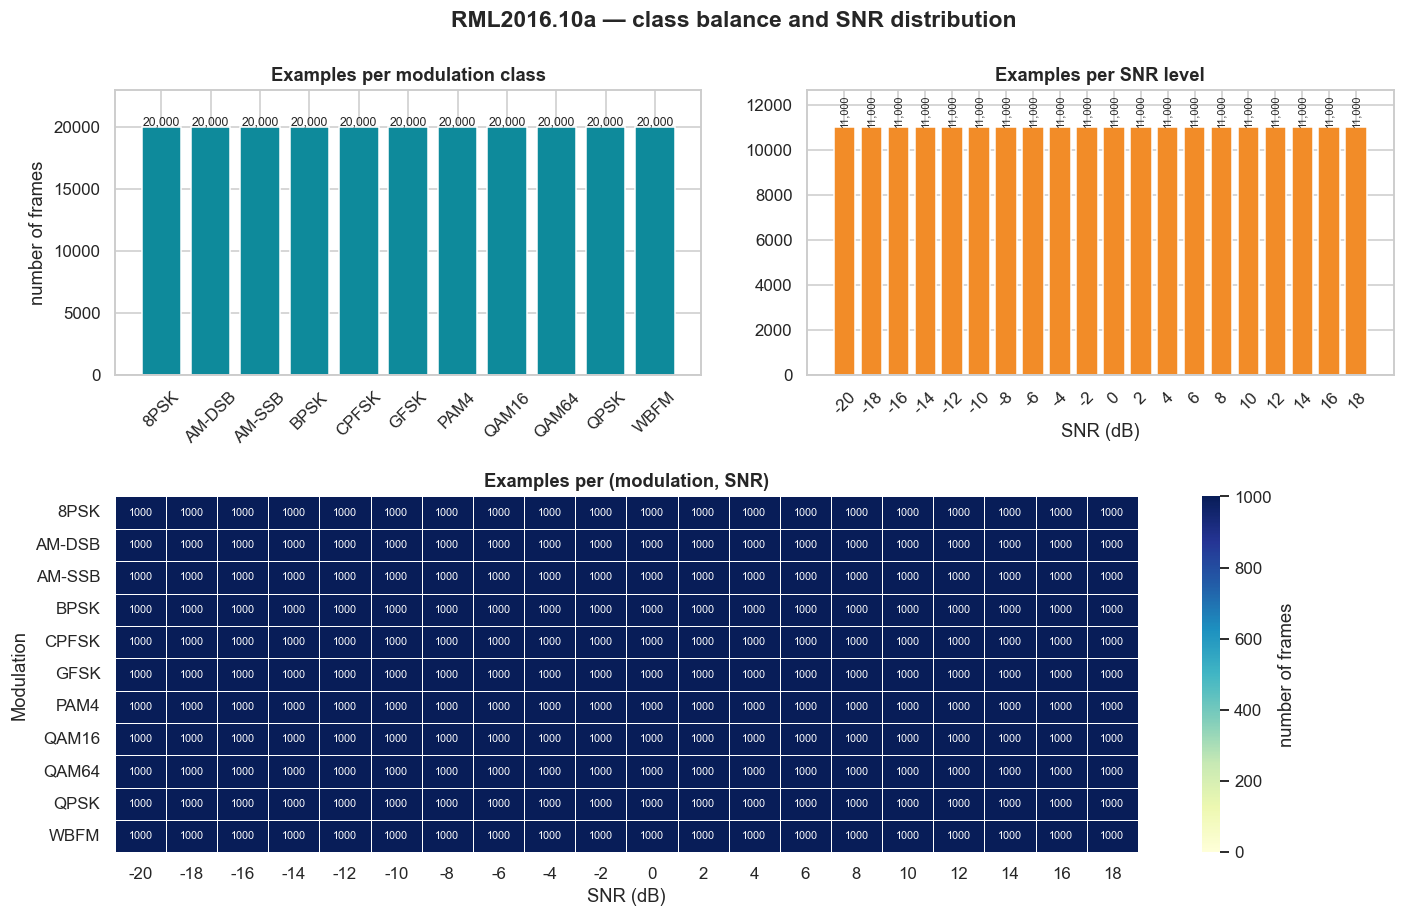

Metric,Value
"Smallest (mod, SNR) group","1,000"
"Largest (mod, SNR) group","1,000"
"Imbalance ratio (max/min) per (mod, SNR)",1.00
Imbalance ratio per class,1.00
Imbalance ratio per SNR,1.00
Verdict,balanced ✔


In [14]:
fig = plt.figure(figsize=(15, 9))
gs = GridSpec(2, 2, height_ratios=[1, 1.25], hspace=0.38, wspace=0.18)

ax1 = fig.add_subplot(gs[0, 0])
tot_c = counts.sum(axis=1)
ax1.bar(tot_c.index, tot_c.values, color=TEAL)
ax1.set_title("Examples per modulation class"); ax1.set_ylabel("number of frames"); ax1.set_ylim(0, tot_c.max() * 1.15)
ax1.tick_params(axis="x", rotation=45)
for i, v in enumerate(tot_c.values): ax1.text(i, v * 1.01, f"{v:,}", ha="center", fontsize=8)

ax2 = fig.add_subplot(gs[0, 1])
tot_s = counts.sum(axis=0)
ax2.bar([str(s) for s in tot_s.index], tot_s.values, color=ORANGE)
ax2.set_title("Examples per SNR level"); ax2.set_xlabel("SNR (dB)"); ax2.tick_params(axis="x", rotation=45); ax2.set_ylim(0, tot_s.max() * 1.15)
for i, v in enumerate(tot_s.values): ax2.text(i, v * 1.01, f"{v:,}", ha="center", fontsize=7, rotation=90)

ax3 = fig.add_subplot(gs[1, :])
sns.heatmap(counts, annot=True, fmt="d", cmap="YlGnBu", vmin=0, annot_kws={"size": 7},
            cbar_kws={"label": "number of frames"}, linewidths=.4, ax=ax3)
ax3.set_title("Examples per (modulation, SNR)")
fig.suptitle("RML2016.10a — class balance and SNR distribution", fontsize=15, fontweight="bold", y=0.96)
fig.savefig(FIG_DIR / "task1_class_snr_distribution.png"); plt.show()

imb = counts.values.max() / counts.values.min()
balance = pd.DataFrame({"Value": [f"{int(counts.values.min()):,}", f"{int(counts.values.max()):,}", f"{imb:.2f}",
                                  f"{tot_c.max()/tot_c.min():.2f}", f"{tot_s.max()/tot_s.min():.2f}",
                                  "balanced ✔" if imb == 1 else "imbalanced ✖"]},
                       index=["Smallest (mod, SNR) group", "Largest (mod, SNR) group", "Imbalance ratio (max/min) per (mod, SNR)",
                              "Imbalance ratio per class", "Imbalance ratio per SNR", "Verdict"])
show(balance.reset_index().rename(columns={"index": "Metric"}), "Balance metrics", hide_index=True)

### A.10.1 How does the signal level behave with SNR? (sanity check)
The mean power of each frame, `mean(I² + Q²)`, is averaged per (modulation, SNR). This tells us whether the SNR can be guessed from the frame amplitude (it should not be if frames are scaled), which matters for the normalisation strategy chosen in Task 3.

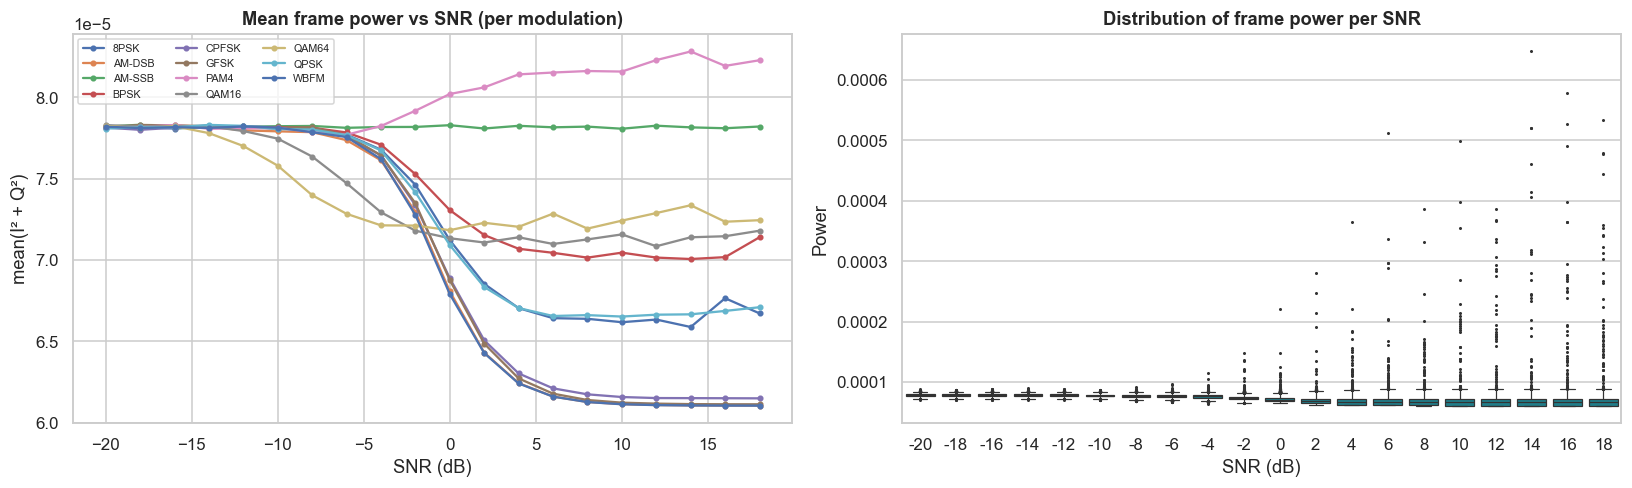

SNR,mean,std,min,max,CV = std/mean
-20.0000,0.0001,0.0000,0.0001,0.0001,0.0290
-18.0000,0.0001,0.0000,0.0001,0.0001,0.0291
-16.0000,0.0001,0.0000,0.0001,0.0001,0.0288
-14.0000,0.0001,0.0000,0.0001,0.0001,0.0289
-12.0000,0.0001,0.0000,0.0001,0.0001,0.0290
-10.0000,0.0001,0.0000,0.0001,0.0001,0.0301
-8.0000,0.0001,0.0000,0.0001,0.0001,0.0328
-6.0000,0.0001,0.0000,0.0001,0.0001,0.0356
-4.0000,0.0001,0.0000,0.0001,0.0001,0.0386
-2.0000,0.0001,0.0000,0.0001,0.0001,0.0474


In [15]:
P = (X[:, 0] ** 2 + X[:, 1] ** 2).mean(axis=1)
dfp = pd.DataFrame({"SNR": snr, "Modulation": pd.Series(y).map(id2label).values, "Power": P})

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
piv = dfp.groupby(["SNR", "Modulation"])["Power"].mean().unstack()
piv.plot(ax=ax[0], lw=1.5, marker="o", ms=3)
ax[0].set_title("Mean frame power vs SNR (per modulation)"); ax[0].set_xlabel("SNR (dB)"); ax[0].set_ylabel("mean(I² + Q²)")
ax[0].legend(ncol=3, fontsize=7)
sns.boxplot(data=dfp, x="SNR", y="Power", color=TEAL, fliersize=1, linewidth=.8, ax=ax[1])
ax[1].set_title("Distribution of frame power per SNR"); ax[1].set_xlabel("SNR (dB)")
plt.tight_layout(); fig.savefig(FIG_DIR / "task1_power_vs_snr.png"); plt.show()

pst = dfp.groupby("SNR")["Power"].agg(["mean", "std", "min", "max"])
pst["CV = std/mean"] = pst["std"] / pst["mean"]
show(pst.reset_index(), "Frame power statistics per SNR", fmt="{:.4f}", hide_index=True)

### A.10.2 First look at the raw signals (one frame per modulation)
Time-domain I and Q of the first frame of each modulation, at a clean SNR and at a very noisy one. (The full visualisation study is **Task 2**.)

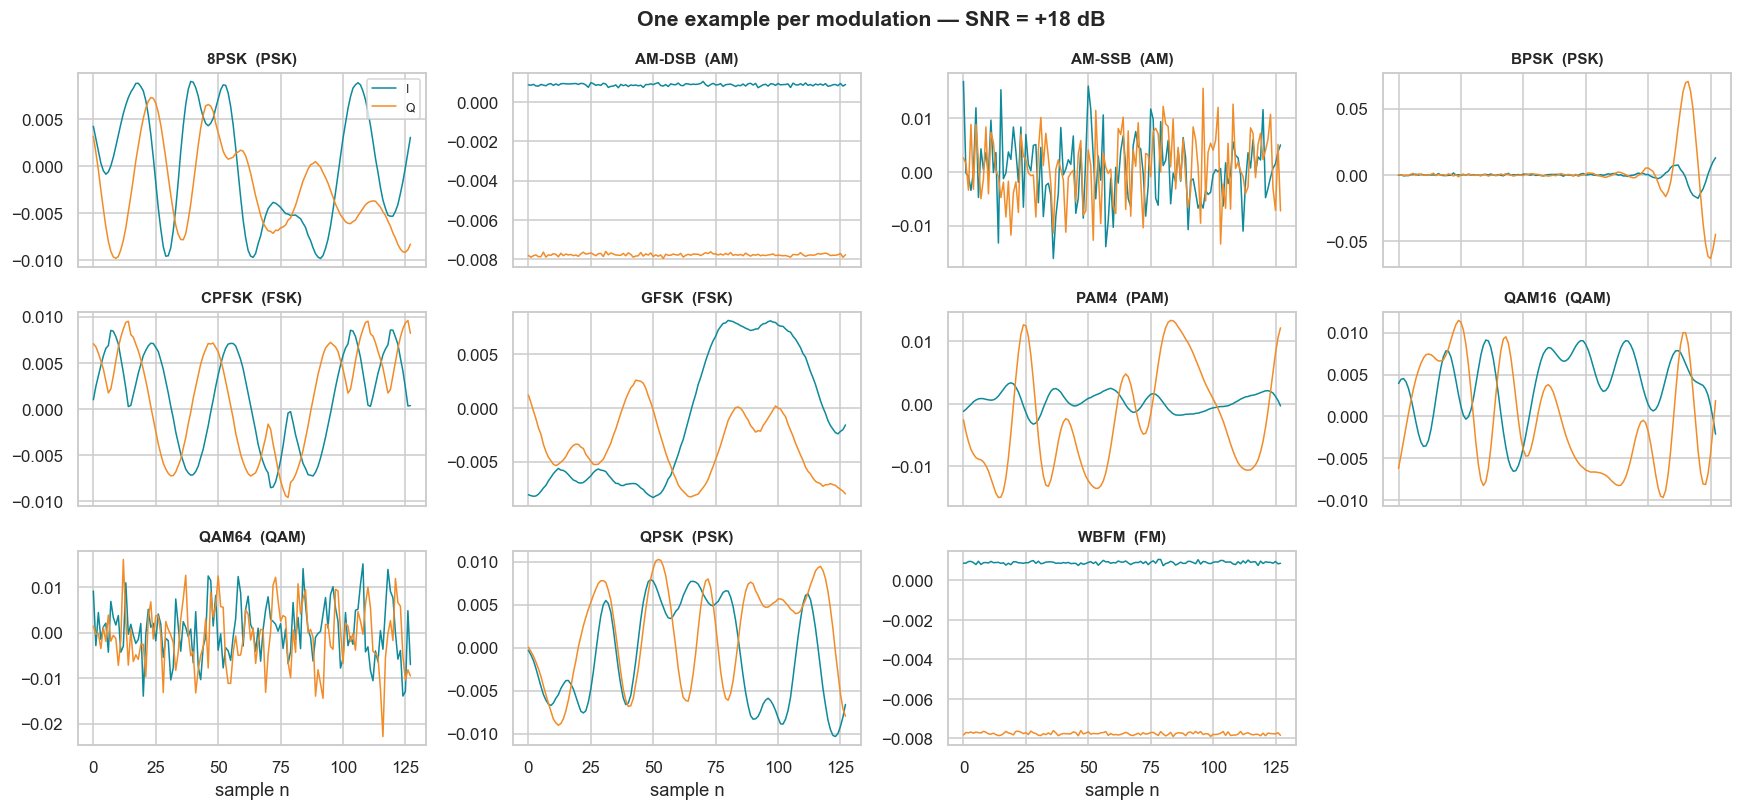

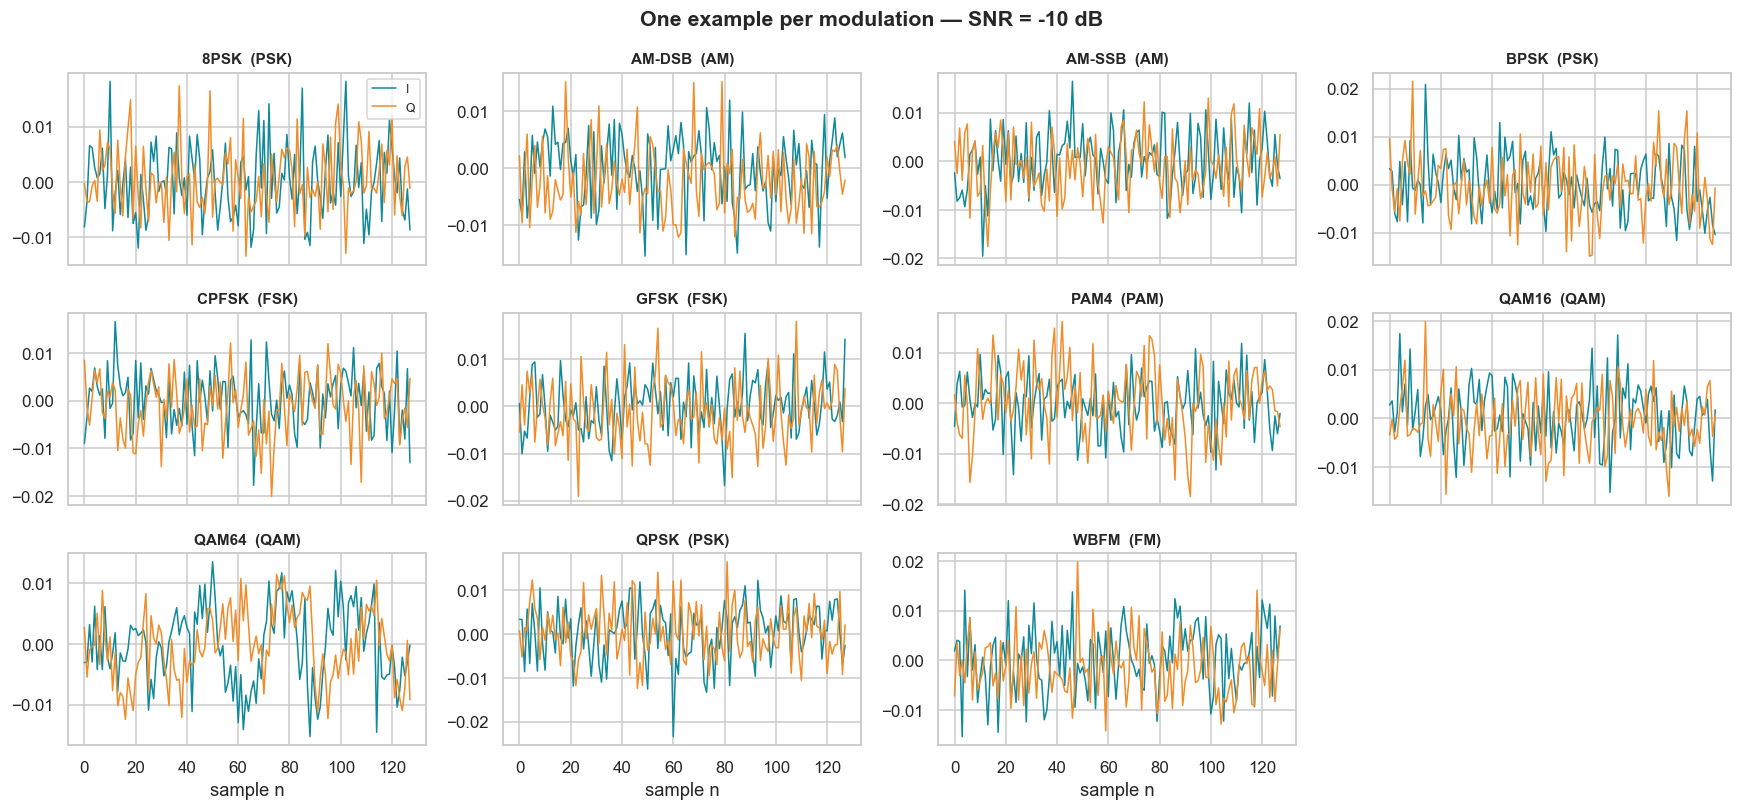

In [16]:
def quick_look(snr_value):
    fig, axes = plt.subplots(3, 4, figsize=(16, 7.5), sharex=True)
    for ax, m in zip(axes.ravel(), mods):
        frame = Xd[(m, snr_value)][0]
        ax.plot(frame[0], lw=1, color=TEAL, label="I"); ax.plot(frame[1], lw=1, color=ORANGE, label="Q")
        ax.set_title(f"{m}  ({MOD_INFO[m][0]})", fontsize=10)
    for ax in axes.ravel()[len(mods):]: ax.axis("off")
    axes[0, 0].legend(loc="upper right", fontsize=8)
    for ax in axes[-1]: ax.set_xlabel("sample n")
    fig.suptitle(f"One example per modulation — SNR = {snr_value:+d} dB", fontsize=14, fontweight="bold")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"task1_quick_look_{snr_value}dB.png"); plt.show()

quick_look(18)
quick_look(-10)

## A.11 Dataset description and summary table

In [17]:
file_bytes = PKL_PATH.stat().st_size
arch_txt   = f"{ARCHIVE_PATH.name}: {ARCHIVE_PATH.stat().st_size:,} B" if ARCHIVE_PATH else "archive not kept"
summary = pd.DataFrame([
    ("Identity",    "Dataset name",                  "RadioML RML2016.10a"),
    ("Identity",    "Source / owner",                "DeepSig Inc. — https://www.deepsig.ai/datasets"),
    ("Identity",    "License",                       "CC BY-NC-SA 4.0"),
    ("Identity",    "Generation",                    "Synthetic (GNU Radio) with channel impairments (noise, fading, LO drift, sample-rate offset)"),
    ("File",        "File name",                     PKL_PATH.name),
    ("File",        "Exact size",                    f"{file_bytes:,} bytes ({human_size(file_bytes)}) | {arch_txt}"),
    ("File",        "Format",                        "Python pickle (Python 2) → load with encoding='latin1'"),
    ("Structure",   "Container",                     "dict {(modulation: str, SNR: int) → ndarray}"),
    ("Structure",   "Array per key",                 f"{next(iter(Xd.values())).shape}  = (examples, I/Q, time samples)"),
    ("Structure",   "Observation shape",             f"{X.shape[1:]} → input 2 × 128"),
    ("Structure",   "Data type",                     str(X.dtype)),
    ("Content",     "Samples per observation (N)",   "128"),
    ("Content",     "Modulation classes",            f"{len(mods)}: " + ", ".join(mods)),
    ("Content",     "   digital",                    ", ".join(m for m in mods if MOD_INFO[m][1] == "Digital")),
    ("Content",     "   analog",                     ", ".join(m for m in mods if MOD_INFO[m][1] == "Analog")),
    ("Content",     "SNR levels",                    f"{len(snrs)}: {snrs[0]} to {snrs[-1]} dB, step {snrs[1]-snrs[0]} dB"),
    ("Size",        "Examples per (mod, SNR)",       f"{int(counts.values.min()):,}"),
    ("Size",        "Examples per class",            f"{int(tot_c.iloc[0]):,}"),
    ("Size",        "Examples per SNR",              f"{int(tot_s.iloc[0]):,}"),
    ("Size",        "Total examples",                f"{len(X):,}"),
    ("Quality",     "Class balance",                 "perfectly balanced" if imb == 1 else f"imbalance ratio {imb:.2f}"),
    ("Quality",     "Missing / invalid values",      "none" if not (has_nan or has_inf) else "present"),
    ("Quality",     "Value range",                   f"[{X.min():.4f}, {X.max():.4f}]"),
], columns=["Category", "Property", "Value"])

show(summary, "RML2016.10a — dataset description and summary table", hide_index=True)


Category,Property,Value
Identity,Dataset name,RadioML RML2016.10a
Identity,Source / owner,DeepSig Inc. — https://www.deepsig.ai/datasets
Identity,License,CC BY-NC-SA 4.0
Identity,Generation,"Synthetic (GNU Radio) with channel impairments (noise, fading, LO drift, sample-rate offset)"
File,File name,RML2016.10a_dict.pkl
File,Exact size,"640,919,653 bytes (611.23 MB) | RML2016.10a.tar.bz2: 228,491,318 B"
File,Format,Python pickle (Python 2) → load with encoding='latin1'
Structure,Container,"dict {(modulation: str, SNR: int) → ndarray}"
Structure,Array per key,"(1000, 2, 128) = (examples, I/Q, time samples)"
Structure,Observation shape,"(2, 128) → input 2 × 128"


> **Citation (must appear in the report):** DeepSig Inc., *RadioML RML2016.10a*, https://www.deepsig.ai/datasets — T. J. O'Shea and N. West, "Radio Machine Learning Dataset Generation with GNU Radio," *Proc. 6th GNU Radio Conference*, 2016. License: CC BY-NC-SA 4.0.

## A.13 Answers to the Task 1 questions

#### 1. What information is represented by the I and Q components?
A real band-pass signal around a carrier $f_c$ can be written
$$x(t)=I(t)\cos(2\pi f_c t)-Q(t)\sin(2\pi f_c t),$$
and its **complex baseband (envelope)** is $s(t)=I(t)+jQ(t)$.
* **I (in-phase)** is the component aligned with the carrier cosine, **Q (quadrature)** the component shifted by 90°.
* Together they give the instantaneous **amplitude** $|s(t)|=\sqrt{I^2+Q^2}$ and **phase** $\varphi(t)=\operatorname{atan2}(Q,I)$, and the **frequency** as the derivative of the phase.
* All the information carried by the modulation sits there: amplitude changes (AM, PAM, QAM), phase changes (PSK) and frequency changes (FSK, FM).

#### 2. Why are complex baseband samples useful for modulation recognition?
* They keep **both amplitude and phase**; a real sample or a magnitude spectrum alone would lose one of them (e.g. BPSK vs QPSK cannot be separated by amplitude).
* The **I/Q plane (constellation)** directly shows the symbol structure: 2 points for BPSK, 4 for QPSK, 8 for 8PSK, 16 for 16-QAM, and so on.
* Working at baseband **removes the carrier**, so the data is compact (128 complex samples per example) and independent of the carrier frequency.
* A neural network can **learn features directly from raw I/Q** instead of relying on hand-crafted features (cumulants, cyclostationary features).

#### 3. What does the SNR represent?
The **signal-to-noise ratio** is the ratio between the signal power and the noise power:
$$\mathrm{SNR_{dB}}=10\log_{10}\frac{P_{signal}}{P_{noise}}.$$
At 0 dB signal and noise have equal power; at −20 dB the noise is 100× stronger than the signal; at +18 dB the signal is about 63× stronger. The lower the SNR, the more the received I/Q points are spread around their ideal positions, so the harder the modulation is to recognise.

#### 4. Why does the dataset contain observations at different SNR values?
In a real receiver the SNR changes with distance, fading, interference and hardware, so a classifier must work in many conditions. Several SNR levels allow us to:
1. train a model that is **robust** to noise;
2. measure the **accuracy as a function of SNR**, the standard performance curve of AMC;
3. find the **SNR threshold** below which classification breaks down;
4. compare architectures **fairly at every noise level**, and not only on average.

---
**Next:** Part B — Task 2 (time-domain, I/Q constellation and FFT visualisation of at least six modulations at −10, 0, +10 and +18 dB).

---
# Part B — Task 2: Signal Visualization and Analysis
**Objective:** connect the wireless-communication concepts (I/Q, noise, SNR, bandwidth) to the signal representations used later by the classifiers.

| # | Required work | Section |
|---|---|---|
| 1 | Select ≥ 6 representative modulations (PSK, QAM, AM/FSK families) | B.1 |
| A | Time-domain: I, Q, and I+Q together, same modulation at SNR = −10, 0, +10, +18 dB | B.2 |
| B | I/Q constellation (Q vs I) and its change with SNR | B.3 |
| C | Magnitude spectrum with FFT (state FFT length, window, normalisation) | B.4 |
| + | Quantitative support: similarity between modulations, envelope variability vs SNR | B.5 |
| Q | Answers to the four Task 2 questions | B.6 |

**Method notes.**
* **Selected modulations (8):** BPSK, QPSK, 8PSK (PSK) · QAM16, QAM64 (QAM) · PAM4 · GFSK (FSK) · AM-DSB (AM).
* **Representative frame.** For each (modulation, SNR) the single-frame plots show the frame whose envelope variability $CV=\sigma_{|s|}/\mu_{|s|}$ is the **median** of the 1,000 frames. Frame 0 is *not* a safe choice: e.g. BPSK at +18 dB, frame 0 has CV = 2.19 (a burst) while the median CV is 0.38.
* **Averaged figures** (density, averaged spectrum) use the same 200 randomly drawn frames (seed 42) for every modulation and SNR.
* **Display normalisation.** Raw amplitudes are tiny (mean frame power ≈ 7·10⁻⁵), so constellation and spectrum plots rescale every frame to unit mean power. This is for visualisation only; the Task 3 normalisation must still be estimated on the training set only.
* No model is trained here, so using the whole dataset for exploratory plots does not create data leakage.

## B.1 Selection of the modulations and configuration

In [18]:
# ---- Task 2 configuration (re-uses Xd, mods, snrs, MOD_INFO, FIG_DIR created in Part A) ----
SEL_MODS  = ["BPSK", "QPSK", "8PSK", "QAM16", "QAM64", "PAM4", "GFSK", "AM-DSB"]
VIS_SNRS  = [-10, 0, 10, 18]          # SNR values required by the project (dB)
N_AVG     = 200                       # frames used for the density and averaged-spectrum figures
FFT_LEN   = 128                       # = N, no zero-padding
WINDOW    = "hann"
SNR_COL   = dict(zip(VIS_SNRS, ["#B22222", ORANGE, TEAL, NAVY]))
LIM       = 2.2                       # axis limit of the constellation plots (frames scaled to unit mean power)

assert all((m, s) in Xd for m in SEL_MODS for s in VIS_SNRS), "selected (modulation, SNR) missing"
AVG_IDX = np.random.default_rng(SEED).choice(Xd[(SEL_MODS[0], VIS_SNRS[0])].shape[0], N_AVG, replace=False)

WHY = {"BPSK": "2 phase states: simplest PSK", "QPSK": "4 phase states", "8PSK": "8 phase states: dense PSK",
       "QAM16": "amplitude + phase, 16 points", "QAM64": "amplitude + phase, 64 points (dense)",
       "PAM4": "4 amplitude levels, real-valued", "GFSK": "frequency modulation, constant envelope",
       "AM-DSB": "analog amplitude modulation"}
sel = pd.DataFrame({"Modulation": SEL_MODS, "Family": [MOD_INFO[m][0] for m in SEL_MODS],
                    "Type": [MOD_INFO[m][1] for m in SEL_MODS], "Why selected": [WHY[m] for m in SEL_MODS]})
show(sel, f"Task 2 — {len(SEL_MODS)} modulations at SNR = {VIS_SNRS} dB", hide_index=True)

# ---- helpers ----
# Representative frame of each (modulation, SNR): the frame whose envelope variability CV = std|s|/mean|s|
# is the MEDIAN of the 1,000 frames. (Frame 0 is sometimes an outlier: e.g. BPSK at +18 dB, frame 0 has CV = 2.19
# whereas the median CV is 0.38, so a naive "first frame" would give a misleading picture.)
REP_IDX = {}
for _m in SEL_MODS:
    for _s in VIS_SNRS:
        _a = np.abs(Xd[(_m, _s)][:, 0] + 1j * Xd[(_m, _s)][:, 1])
        REP_IDX[(_m, _s)] = int(np.argsort(_a.std(axis=1) / _a.mean(axis=1))[_a.shape[0] // 2])

def frame(m, s, i=None):
    """One 2 x 128 frame (row 0 = I, row 1 = Q); default = representative (median-CV) frame."""
    return Xd[(m, s)][REP_IDX[(m, s)] if i is None else i]

def cplx(fr):
    """Complex baseband s[n] = I[n] + j Q[n]."""
    return fr[..., 0, :] + 1j * fr[..., 1, :]

def unit_power(z):
    """Scale each complex frame to unit mean power (visualisation only; nothing is fitted)."""
    return z / np.sqrt(np.mean(np.abs(z) ** 2, axis=-1, keepdims=True))
print("Single-frame figures use the median-CV frame of each (modulation, SNR).")
print("Task 2 uses the full dataset for exploratory plots only (no model is trained, so there is no leakage issue).")

Modulation,Family,Type,Why selected
BPSK,PSK,Digital,2 phase states: simplest PSK
QPSK,PSK,Digital,4 phase states
8PSK,PSK,Digital,8 phase states: dense PSK
QAM16,QAM,Digital,"amplitude + phase, 16 points"
QAM64,QAM,Digital,"amplitude + phase, 64 points (dense)"
PAM4,PAM,Digital,"4 amplitude levels, real-valued"
GFSK,FSK,Digital,"frequency modulation, constant envelope"
AM-DSB,AM,Analog,analog amplitude modulation


Single-frame figures use the median-CV frame of each (modulation, SNR).
Task 2 uses the full dataset for exploratory plots only (no model is trained, so there is no leakage issue).


## B.2 Time-domain visualisation
For each modulation: row 1 = $I[n]$, row 2 = $Q[n]$, row 3 = both superimposed; the four columns are the four SNR values. All panels of one figure share the same axes so that the amplitude of the noise can be compared directly.

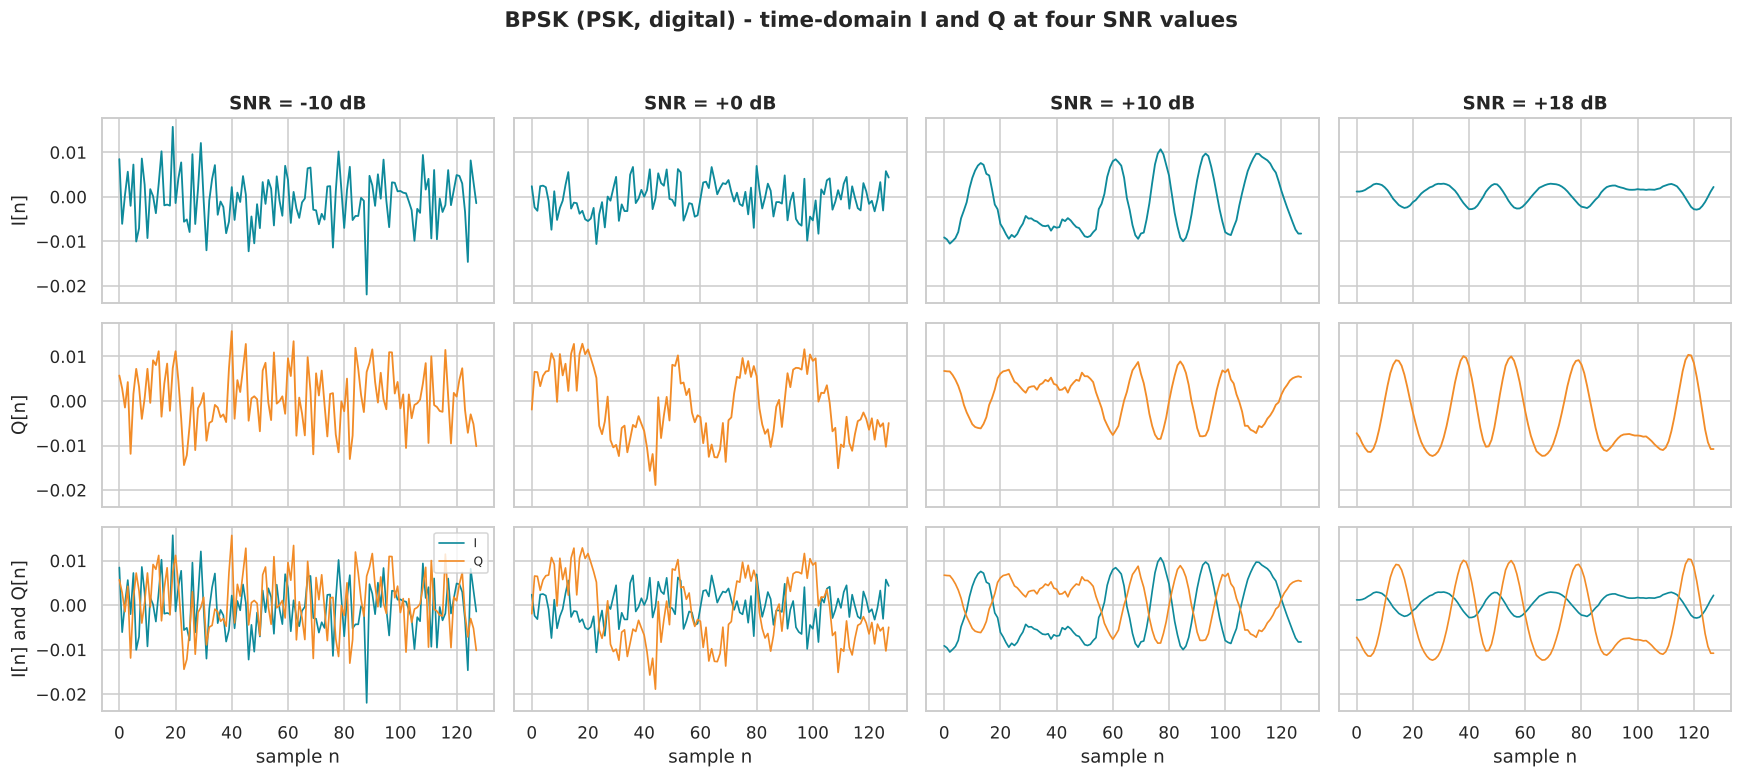

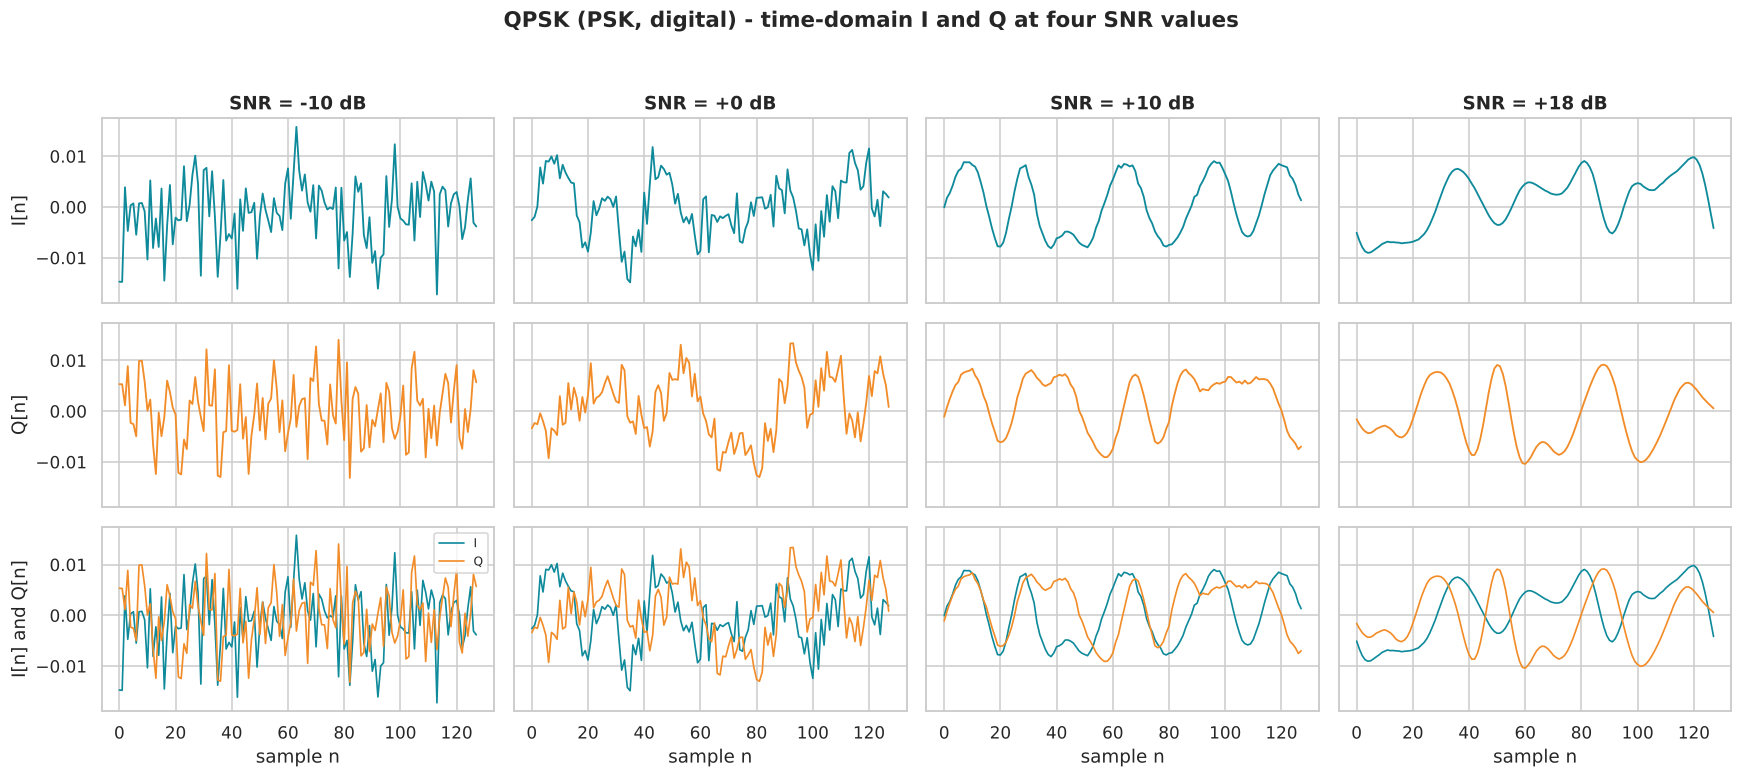

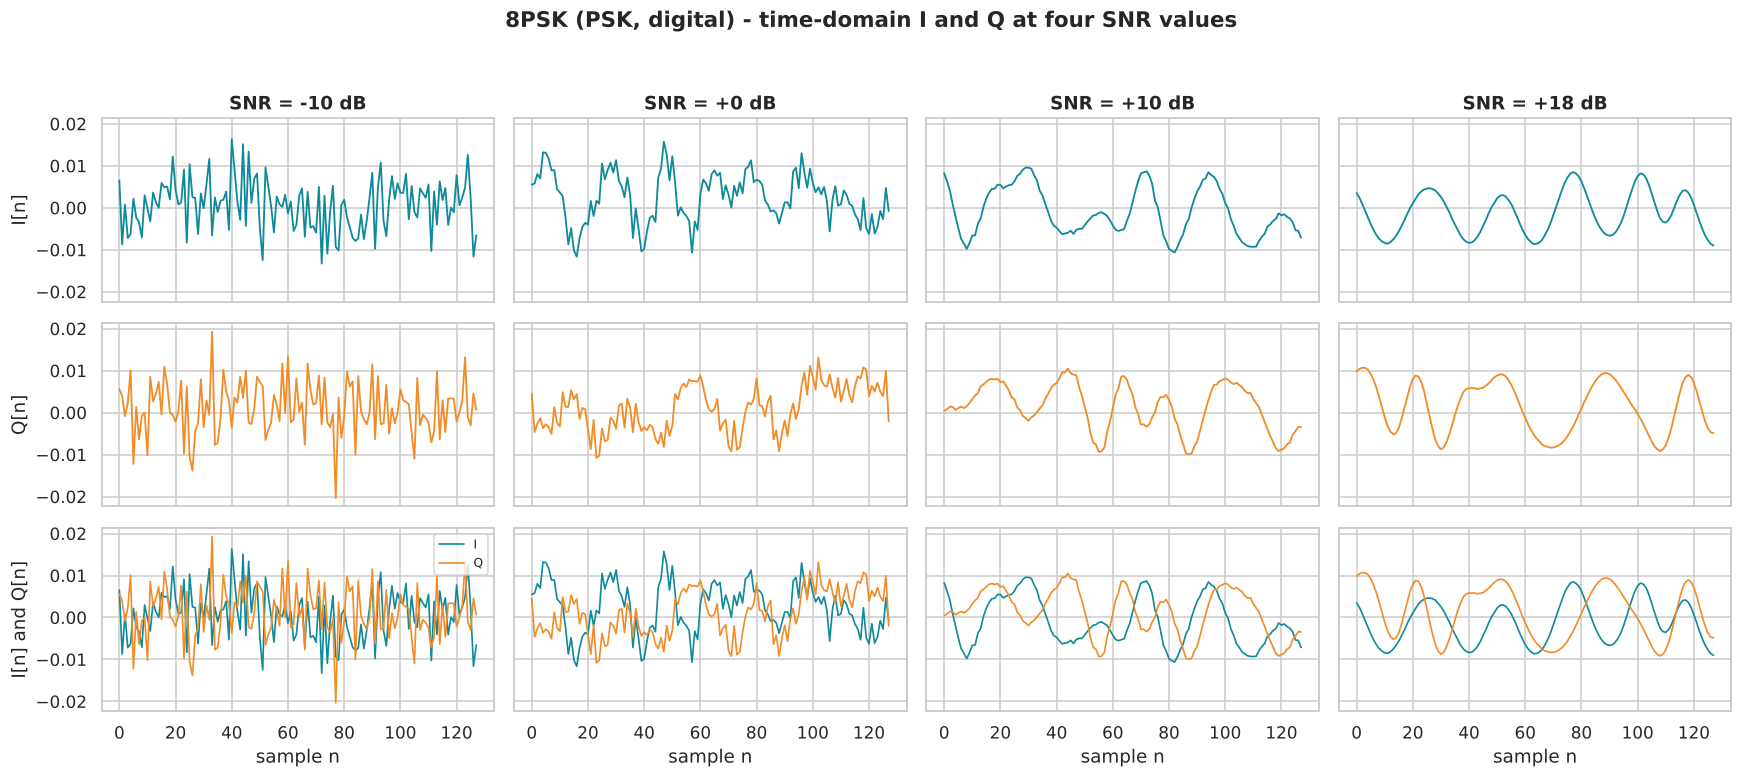

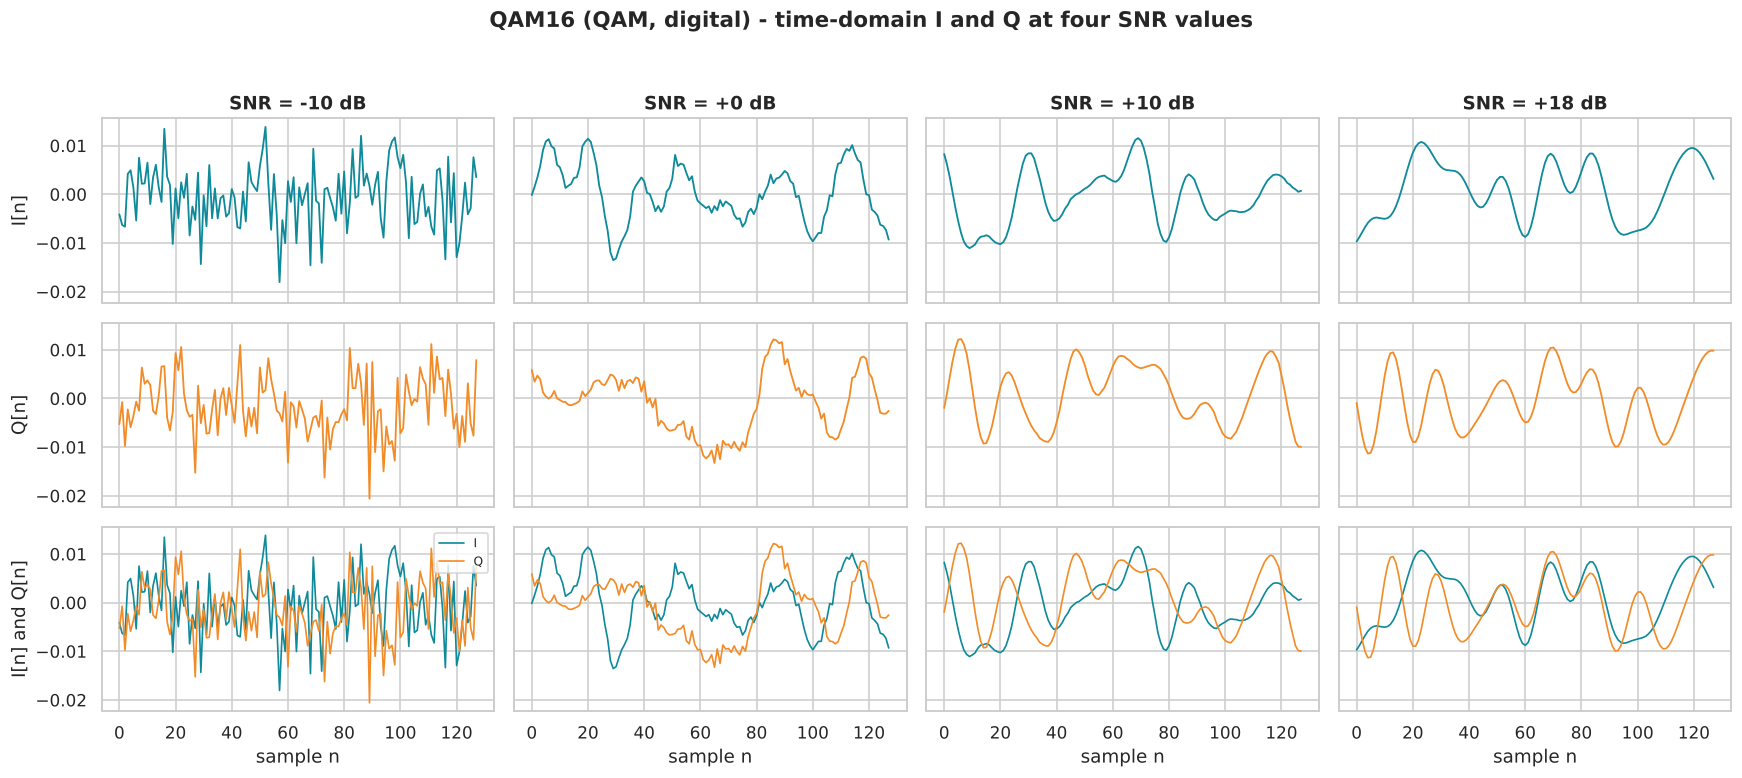

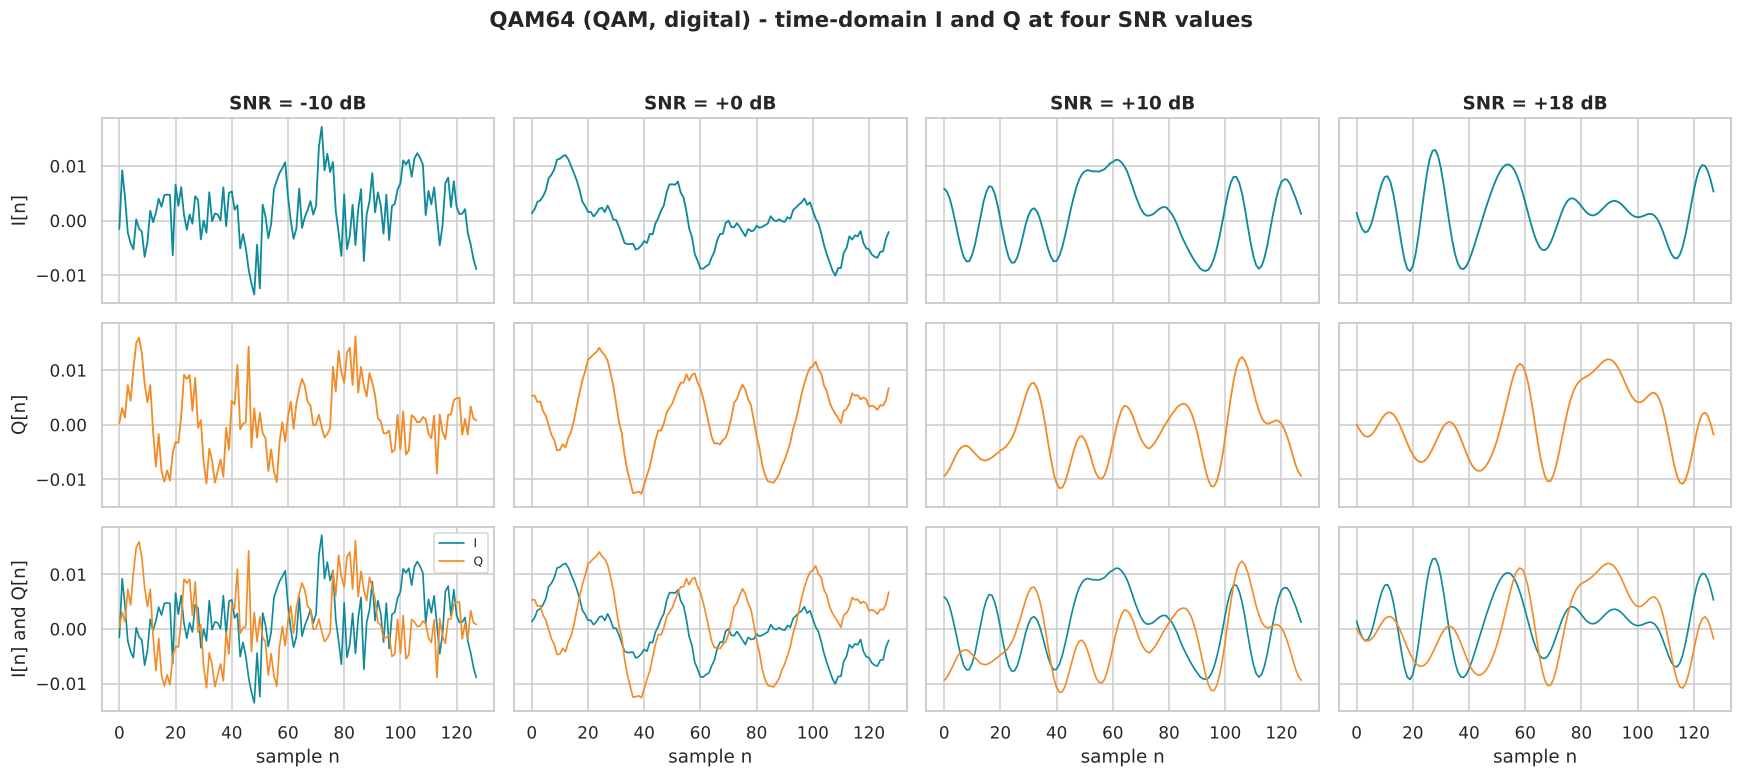

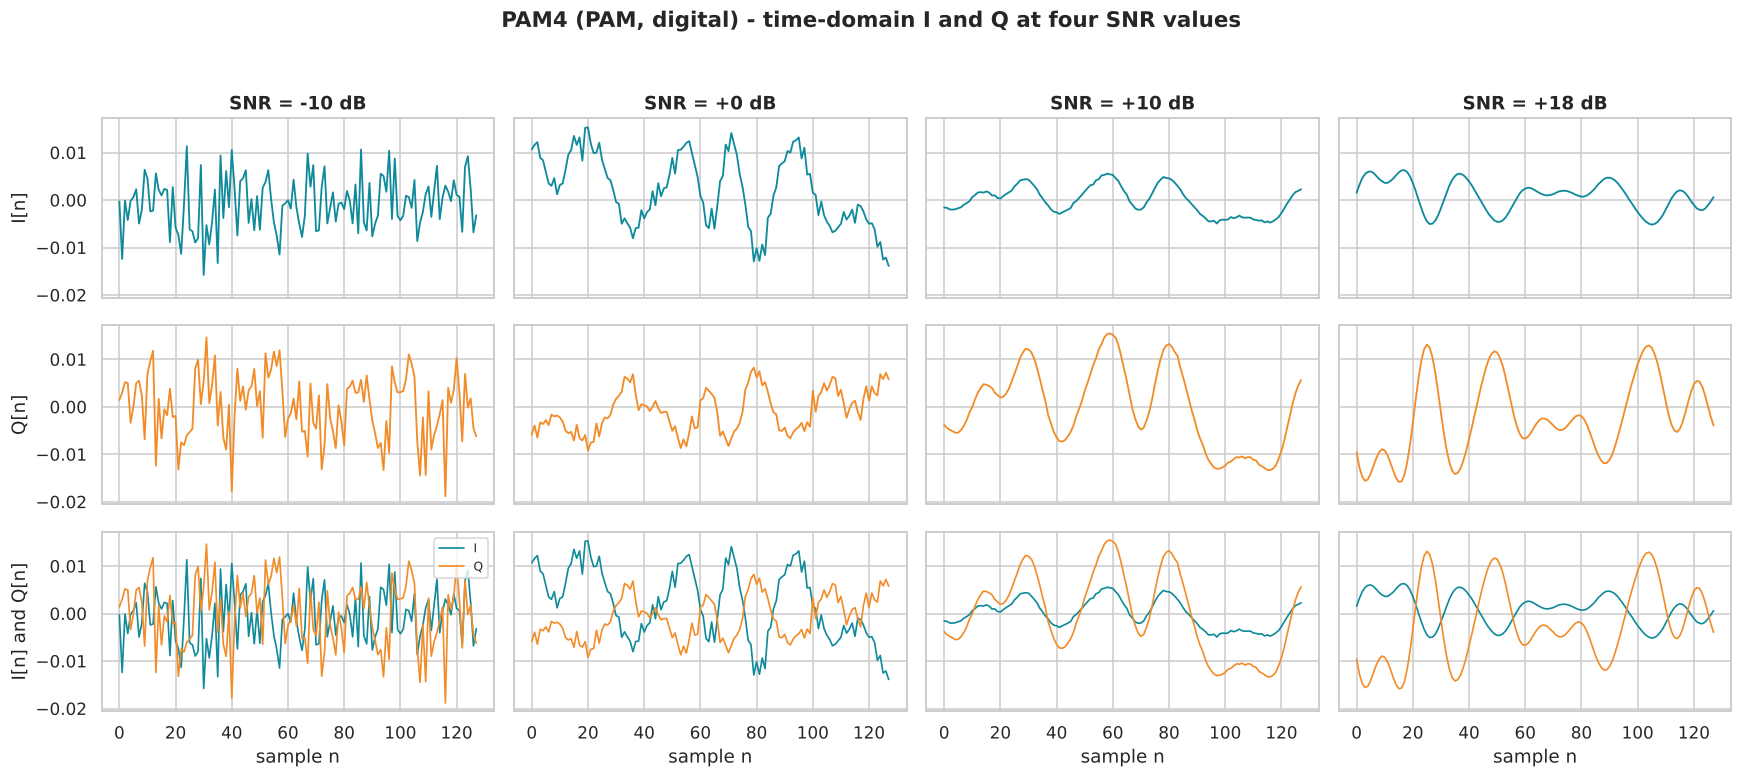

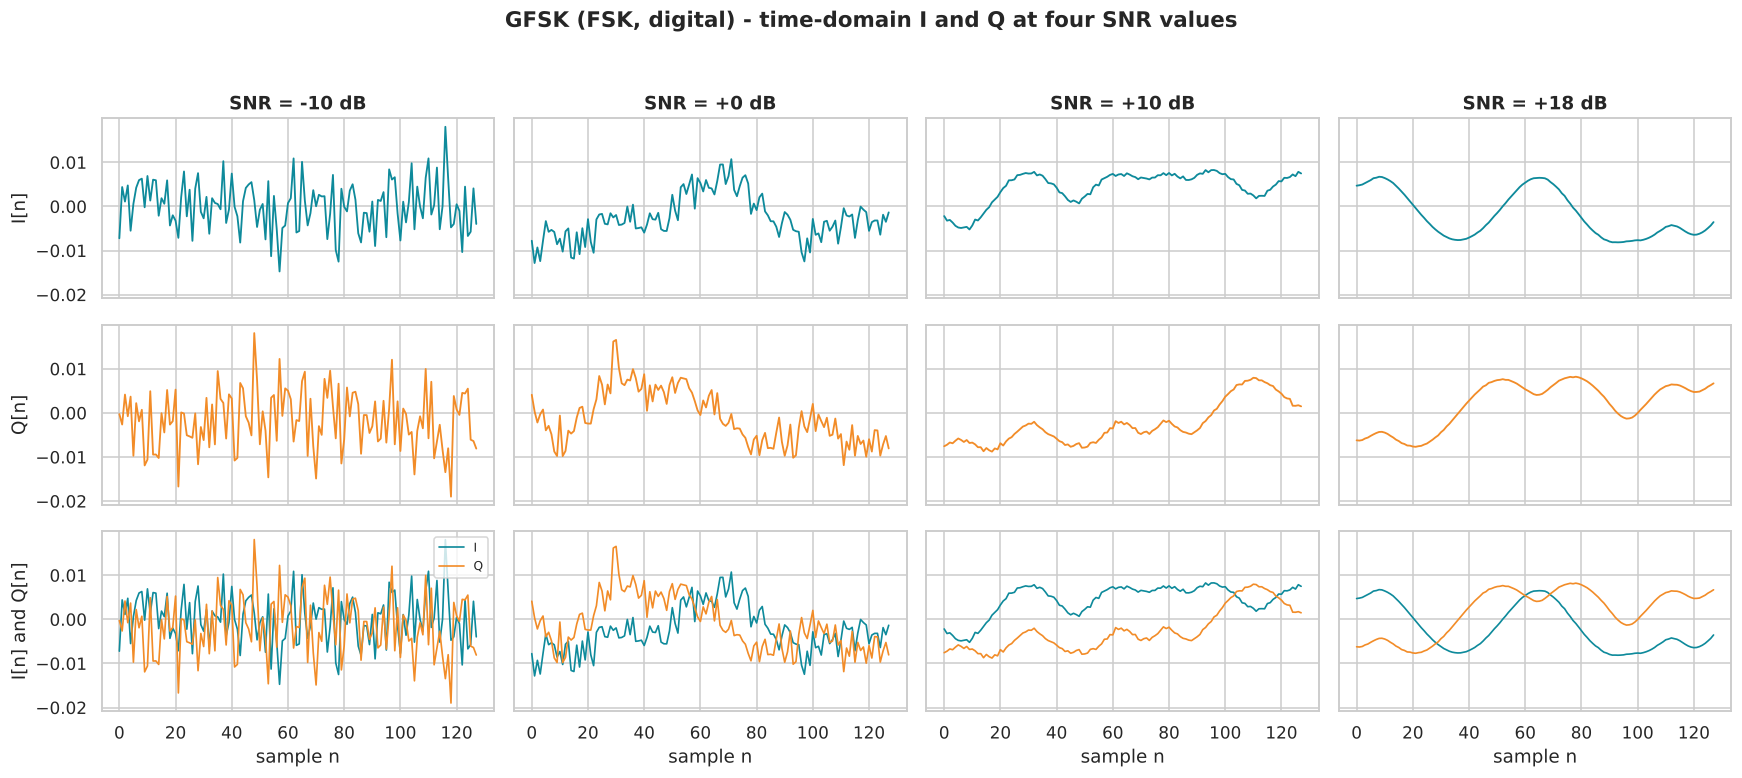

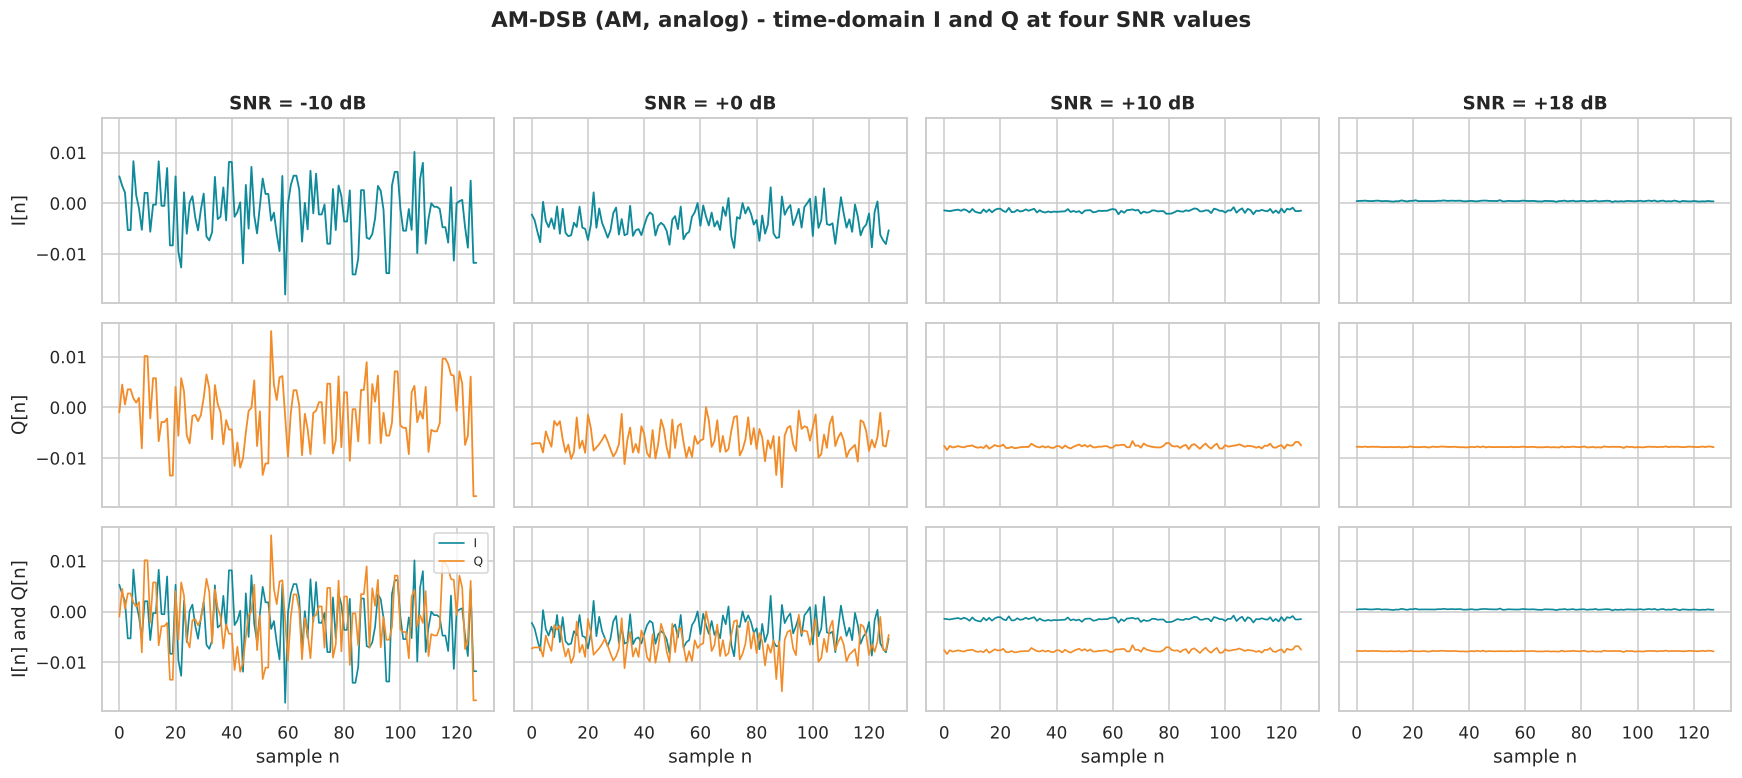

In [19]:
def plot_time_domain(m):
    fig, axes = plt.subplots(3, len(VIS_SNRS), figsize=(16, 7.2), sharex=True, sharey=True)
    for j, s in enumerate(VIS_SNRS):
        I, Q = frame(m, s)
        axes[0, j].plot(I, color=TEAL, lw=1.2)
        axes[1, j].plot(Q, color=ORANGE, lw=1.2)
        axes[2, j].plot(I, color=TEAL, lw=1.1, label="I"); axes[2, j].plot(Q, color=ORANGE, lw=1.1, label="Q")
        axes[0, j].set_title(f"SNR = {s:+d} dB"); axes[2, j].set_xlabel("sample n")
    axes[0, 0].set_ylabel("I[n]"); axes[1, 0].set_ylabel("Q[n]"); axes[2, 0].set_ylabel("I[n] and Q[n]")
    axes[2, 0].legend(loc="upper right", fontsize=8)
    fig.suptitle(f"{m} ({MOD_INFO[m][0]}, {MOD_INFO[m][1].lower()}) - time-domain I and Q at four SNR values",
                 fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95]); fig.savefig(FIG_DIR / f"task2_time_{m}.png"); plt.show()

for m in SEL_MODS:
    plot_time_domain(m)

### B.2.1 What the time domain reveals at a clean SNR
Envelope $|s[n]|=\sqrt{I^2+Q^2}$ (top) and instantaneous frequency $\frac{1}{2\pi}\,\Delta\arg s[n]$ (bottom) at +18 dB. These two quantities are where amplitude, phase and frequency modulation show up.

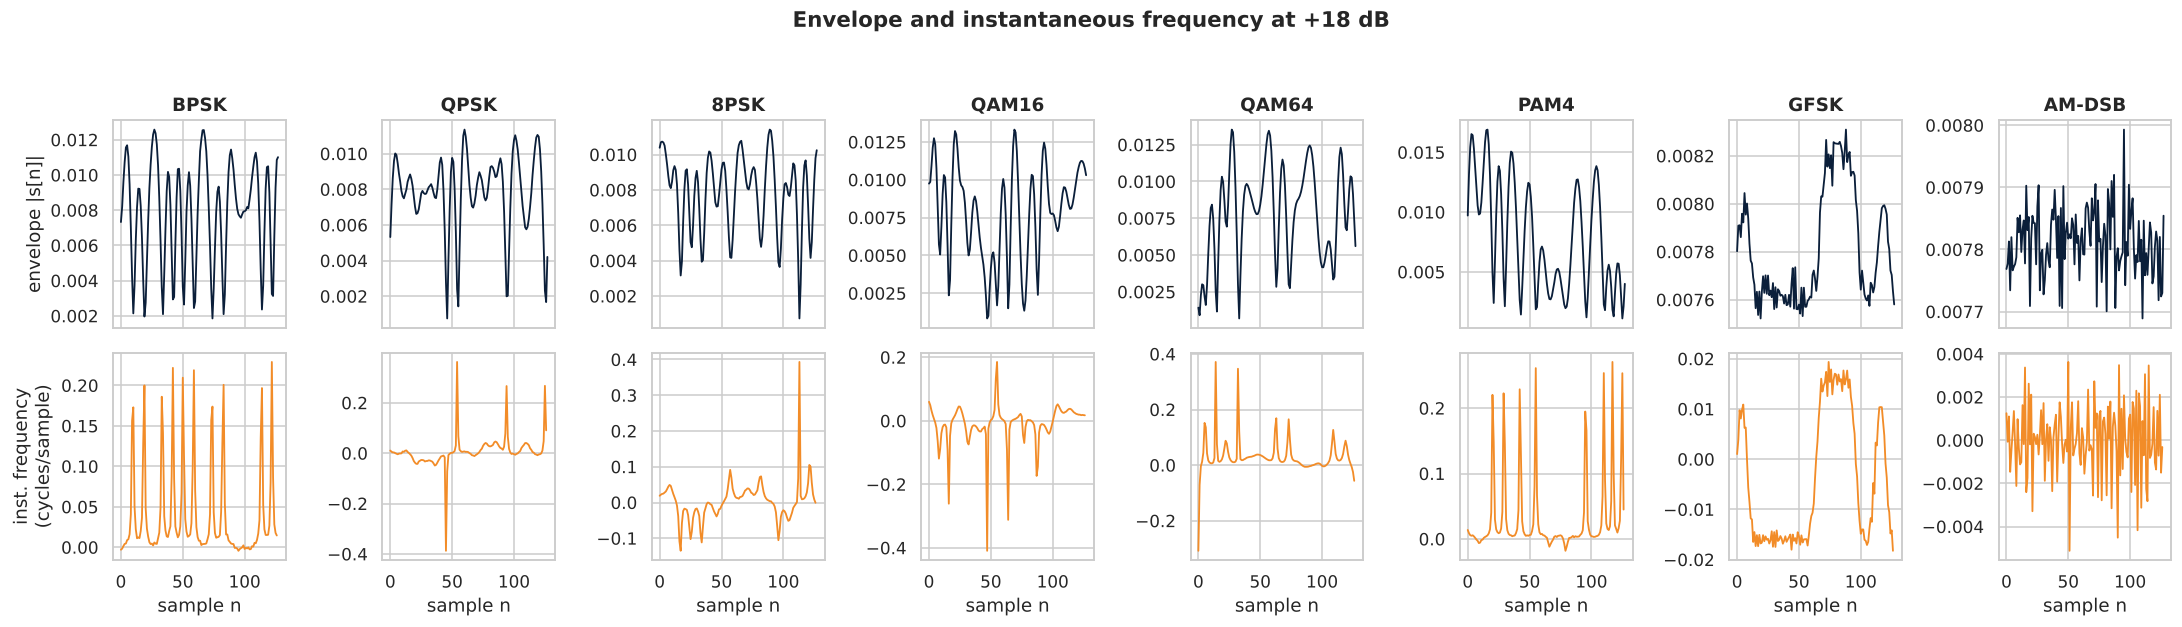

In [20]:
# What the time domain reveals at a clean SNR: envelope |s[n]| and instantaneous frequency
fig, axes = plt.subplots(2, len(SEL_MODS), figsize=(20, 5.8), sharex=True)
for j, m in enumerate(SEL_MODS):
    z = cplx(frame(m, 18))
    axes[0, j].plot(np.abs(z), color=NAVY, lw=1.2)
    axes[1, j].plot(np.diff(np.unwrap(np.angle(z))) / (2 * np.pi), color=ORANGE, lw=1.2)
    axes[0, j].set_title(m); axes[1, j].set_xlabel("sample n")
axes[0, 0].set_ylabel("envelope |s[n]|"); axes[1, 0].set_ylabel("inst. frequency\n(cycles/sample)")
fig.suptitle("Envelope and instantaneous frequency at +18 dB", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94]); fig.savefig(FIG_DIR / "task2_envelope_freq_18dB.png"); plt.show()

## B.3 I/Q constellation visualisation
**Single frame** (128 points, coloured by sample index, grey line = time order). The signal is **oversampled** (pulse-shaped), so the points follow continuous trajectories instead of sitting on a few ideal symbol positions.

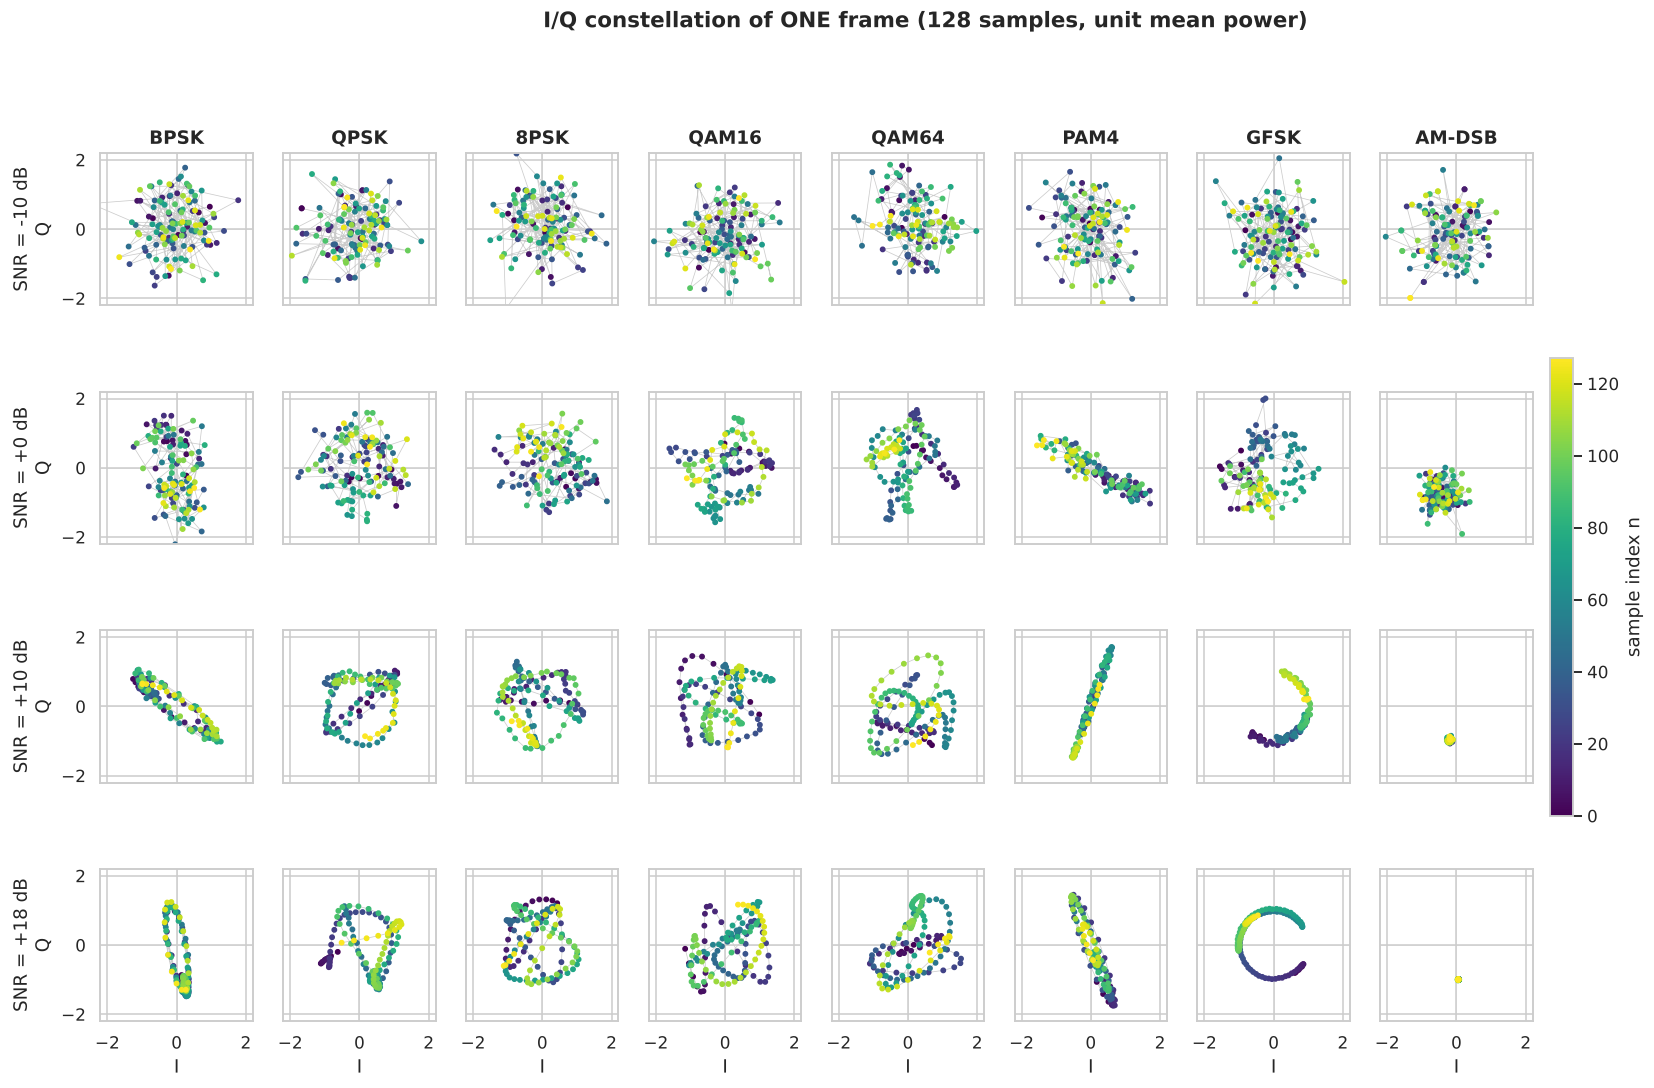

In [21]:
fig, axes = plt.subplots(len(VIS_SNRS), len(SEL_MODS), figsize=(20, 10.8), sharex=True, sharey=True)
for i, s in enumerate(VIS_SNRS):
    for j, m in enumerate(SEL_MODS):
        z = unit_power(cplx(frame(m, s))); ax = axes[i, j]
        ax.plot(z.real, z.imag, color="0.8", lw=0.5, zorder=1)
        sc = ax.scatter(z.real, z.imag, c=np.arange(len(z)), cmap="viridis", s=8, zorder=2)
        ax.axhline(0, color="0.9", lw=.6, zorder=0); ax.axvline(0, color="0.9", lw=.6, zorder=0)
        ax.set_xlim(-LIM, LIM); ax.set_ylim(-LIM, LIM); ax.set_aspect("equal")
        if i == 0: ax.set_title(m)
        if j == 0: ax.set_ylabel(f"SNR = {s:+d} dB\nQ")
        if i == len(VIS_SNRS) - 1: ax.set_xlabel("I")
fig.colorbar(sc, ax=axes, shrink=.5, pad=.01, label="sample index n")
fig.suptitle("I/Q constellation of ONE frame (128 samples, unit mean power)", fontsize=14, fontweight="bold")
fig.savefig(FIG_DIR / "task2_constellation_frame.png"); plt.show()

**Density of 200 frames** (25,600 points per panel). Averaging many frames shows the *typical* structure and removes the frame-to-frame randomness of the single-frame plots.

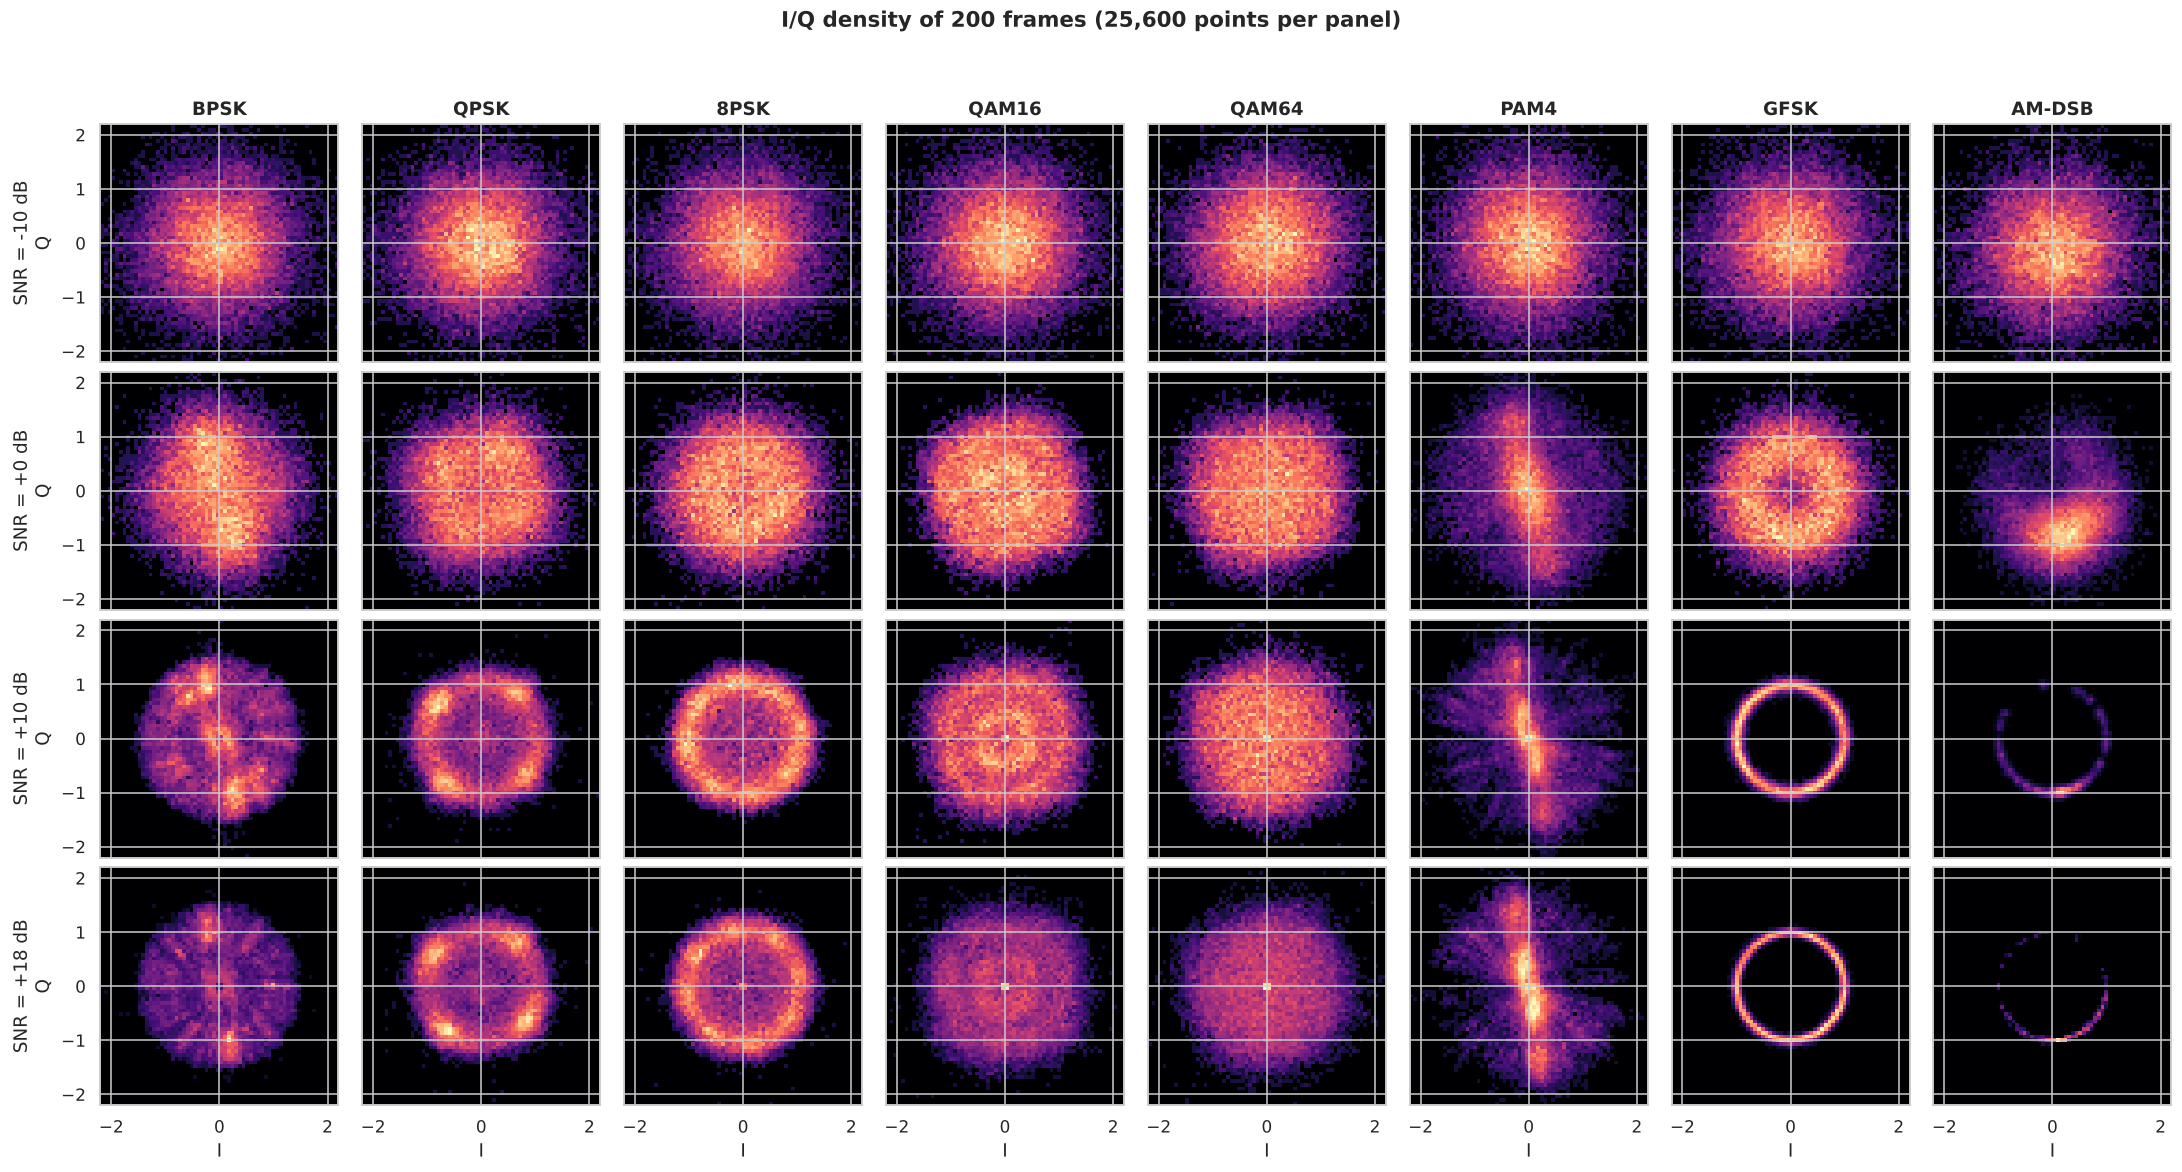

In [22]:
def density(m, s, bins=64):
    """2-D histogram of the I/Q points of N_AVG frames (each frame scaled to unit mean power)."""
    z = unit_power(cplx(Xd[(m, s)][AVG_IDX]))
    H, _, _ = np.histogram2d(z.real.ravel(), z.imag.ravel(), bins=bins, range=[[-LIM, LIM], [-LIM, LIM]])
    return H / H.sum()

DENS = {(m, s): density(m, s) for m in SEL_MODS for s in VIS_SNRS}
from matplotlib.colors import PowerNorm
fig, axes = plt.subplots(len(VIS_SNRS), len(SEL_MODS), figsize=(20, 10.8), sharex=True, sharey=True)
for i, s in enumerate(VIS_SNRS):
    for j, m in enumerate(SEL_MODS):
        ax = axes[i, j]
        ax.imshow(DENS[(m, s)].T, origin="lower", extent=[-LIM, LIM, -LIM, LIM], cmap="magma", norm=PowerNorm(0.5))
        if i == 0: ax.set_title(m)
        if j == 0: ax.set_ylabel(f"SNR = {s:+d} dB\nQ")
        if i == len(VIS_SNRS) - 1: ax.set_xlabel("I")
fig.suptitle(f"I/Q density of {N_AVG} frames ({N_AVG * 128:,} points per panel)", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95]); fig.savefig(FIG_DIR / "task2_constellation_density.png"); plt.show()

## B.4 Frequency-domain visualisation
For a complex frame $s[n]=I[n]+jQ[n]$ (after the unit-power rescaling) the magnitude spectrum is
$$S[k]=\frac{1}{\sum_n w[n]}\sum_{n=0}^{127} w[n]\,s[n]\,e^{-j2\pi kn/128},\qquad |S[k]|_{dB}=20\log_{10}|S[k]|,$$
with a **Hann window** $w[n]$, **FFT length 128** (= N, no zero-padding), `fftshift` so that 0 is centred, and the frequency axis in cycles/sample. Because $s$ is complex, positive and negative frequencies are different, so the whole band $[-0.5, 0.5)$ is plotted.
The first figure is a single frame (noisy by nature: one periodogram has a large variance); the second is the power average over 200 frames.

FFT length = 128 (no zero-padding) | window = hann | magnitude divided by sum(window) | frames scaled to unit power


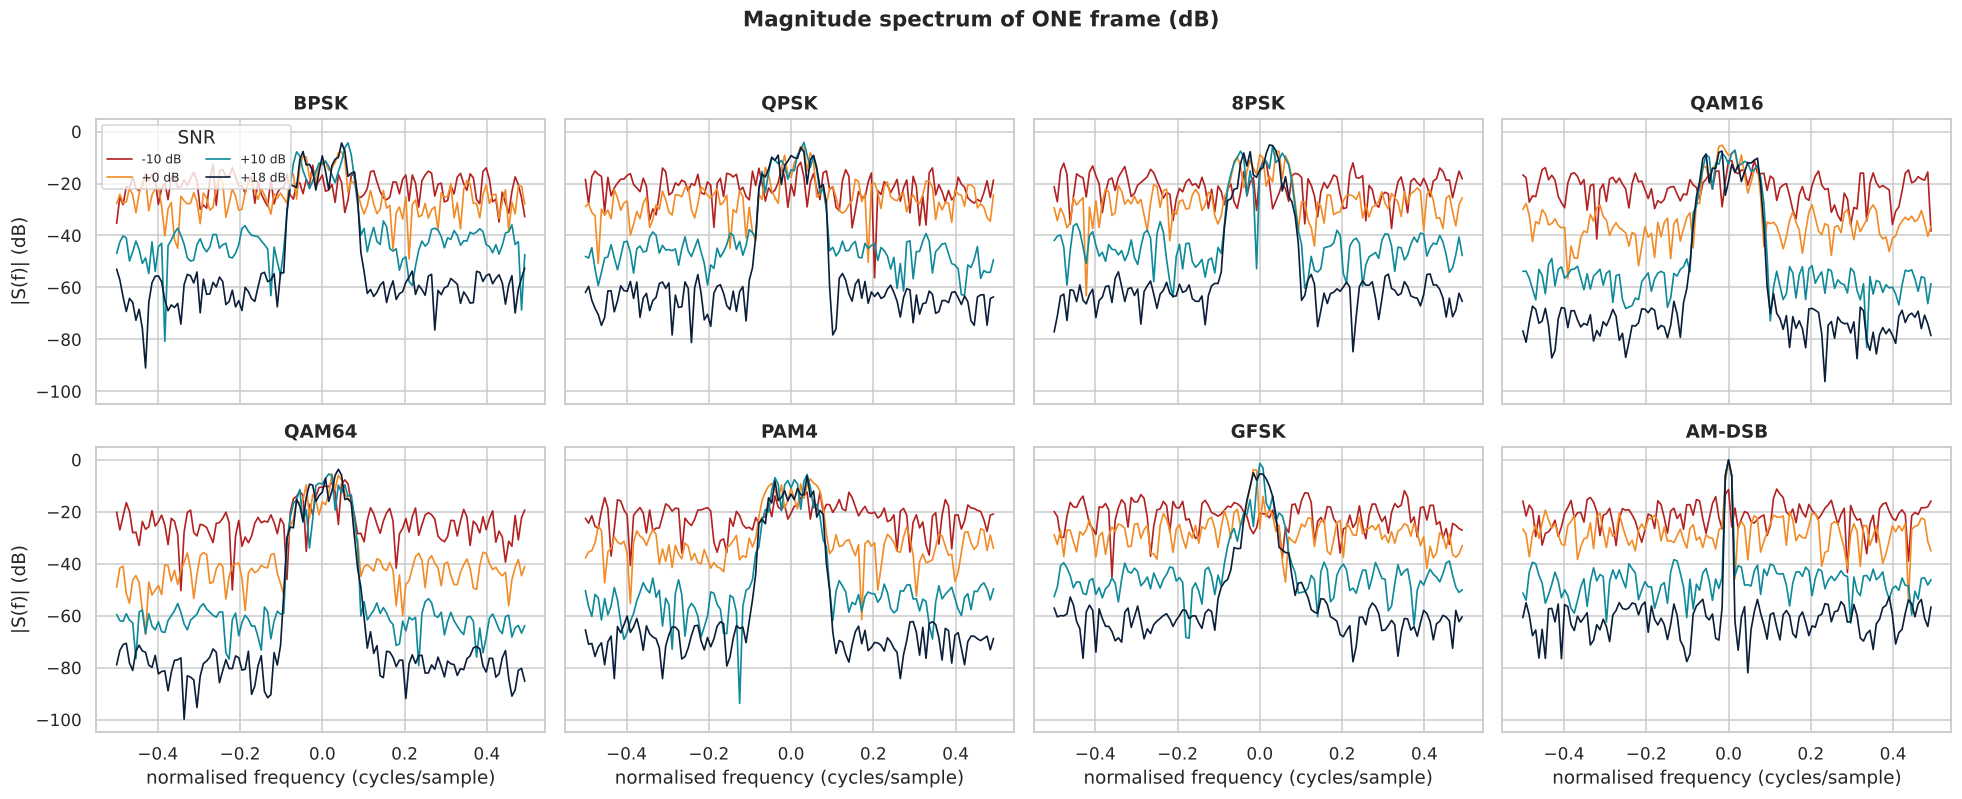

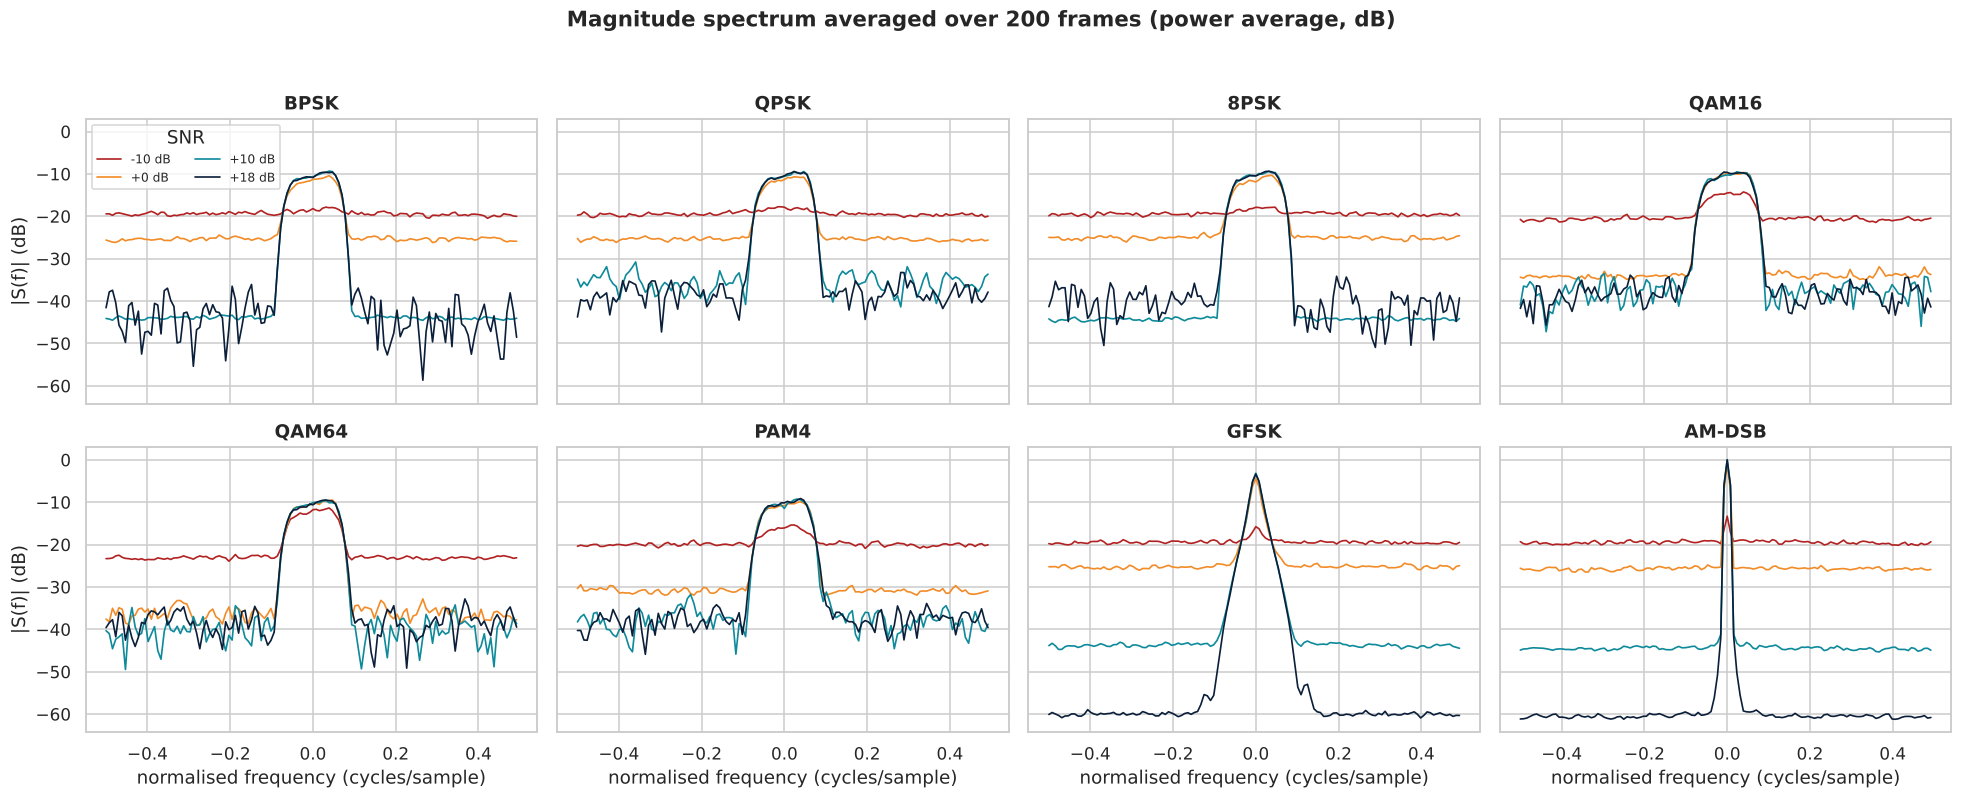

In [23]:
win   = sp_signal.get_window(WINDOW, FFT_LEN)
freqs = fftshift(fftfreq(FFT_LEN))                      # normalised frequency, cycles/sample

def spectrum(z):
    """Windowed FFT of complex frames (last axis = time), centred at 0 and divided by sum(window)."""
    return fftshift(fft(unit_power(z) * win, n=FFT_LEN, axis=-1), axes=-1) / win.sum()

def spec_single_db(m, s):  return 20 * np.log10(np.abs(spectrum(cplx(frame(m, s)))) + 1e-12)
def spec_avg_db(m, s):     return 10 * np.log10(np.mean(np.abs(spectrum(cplx(Xd[(m, s)][AVG_IDX]))) ** 2, axis=0) + 1e-12)

def plot_spectra(fn, title, fname):
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.4), sharex=True, sharey=True)
    for ax, m in zip(axes.ravel(), SEL_MODS):
        for s in VIS_SNRS:
            ax.plot(freqs, fn(m, s), color=SNR_COL[s], lw=1.1, label=f"{s:+d} dB")
        ax.set_title(m)
    for ax in axes[-1]: ax.set_xlabel("normalised frequency (cycles/sample)")
    for ax in axes[:, 0]: ax.set_ylabel("|S(f)| (dB)")
    axes[0, 0].legend(title="SNR", fontsize=8, loc="upper left", ncol=2)
    fig.suptitle(title, fontsize=14, fontweight="bold"); fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(FIG_DIR / fname); plt.show()

print(f"FFT length = {FFT_LEN} (no zero-padding) | window = {WINDOW} | magnitude divided by sum(window) | frames scaled to unit power")
plot_spectra(spec_single_db, "Magnitude spectrum of ONE frame (dB)", "task2_fft_single_frame.png")
plot_spectra(spec_avg_db, f"Magnitude spectrum averaged over {N_AVG} frames (power average, dB)", "task2_fft_averaged.png")

Same averaged spectra, but all modulations overlaid: this is the check of what a spectrum alone can (and cannot) separate.

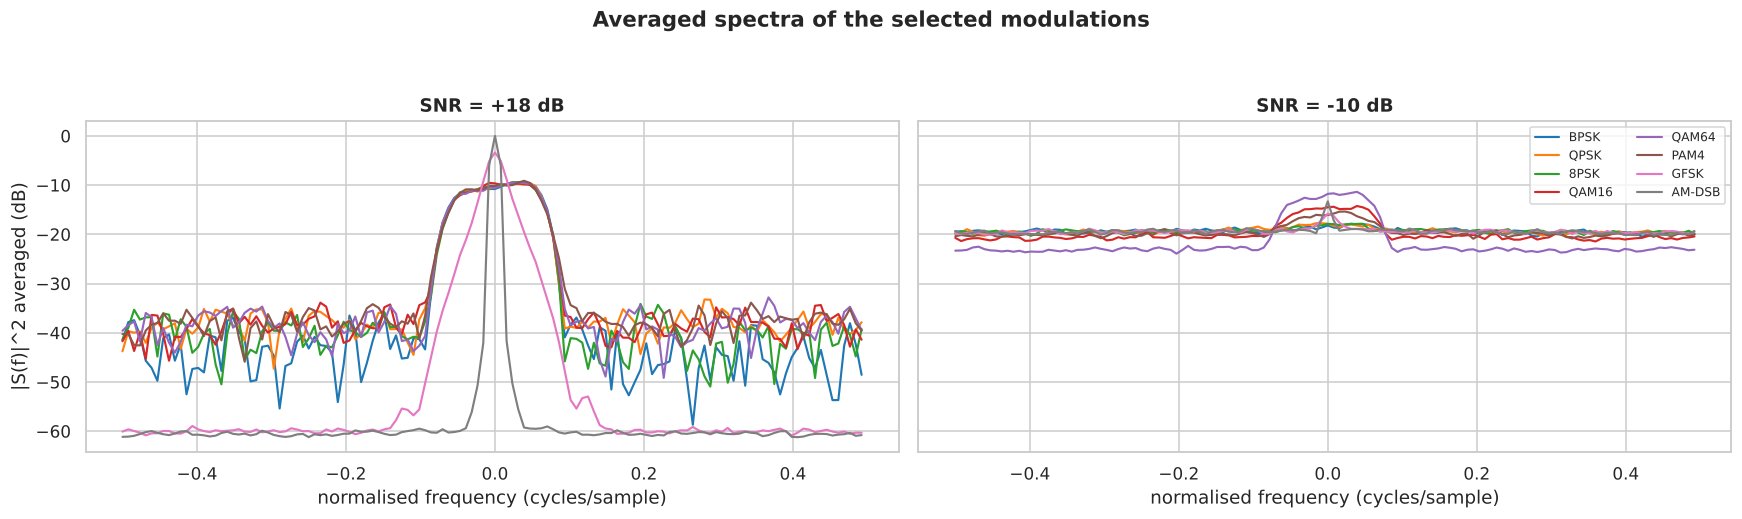

In [24]:
# Which modulations can the SPECTRUM alone separate?  (averaged spectra overlaid)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
pal = sns.color_palette("tab10", len(SEL_MODS))
for ax, s in zip(axes, [18, -10]):
    for c, m in zip(pal, SEL_MODS): ax.plot(freqs, spec_avg_db(m, s), color=c, lw=1.4, label=m)
    ax.set_title(f"SNR = {s:+d} dB"); ax.set_xlabel("normalised frequency (cycles/sample)")
axes[0].set_ylabel("|S(f)|^2 averaged (dB)"); axes[1].legend(ncol=2, fontsize=8)
fig.suptitle("Averaged spectra of the selected modulations", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93]); fig.savefig(FIG_DIR / "task2_fft_compare.png"); plt.show()

## B.5 Quantitative support for the visual impressions
Two simple, reproducible measures (they are illustrative, **not** a classifier):
1. **Cosine similarity** between modulations, using the I/Q density map and the averaged spectrum as feature vectors (1 = identical shape).
2. **Envelope variability** $CV=\sigma_{|s|}/\mu_{|s|}$ vs SNR over all 20 SNR levels. For pure complex Gaussian noise the envelope is Rayleigh distributed and $CV=\sqrt{4/\pi-1}\approx0.523$, so every modulation should converge to that value when the noise dominates.

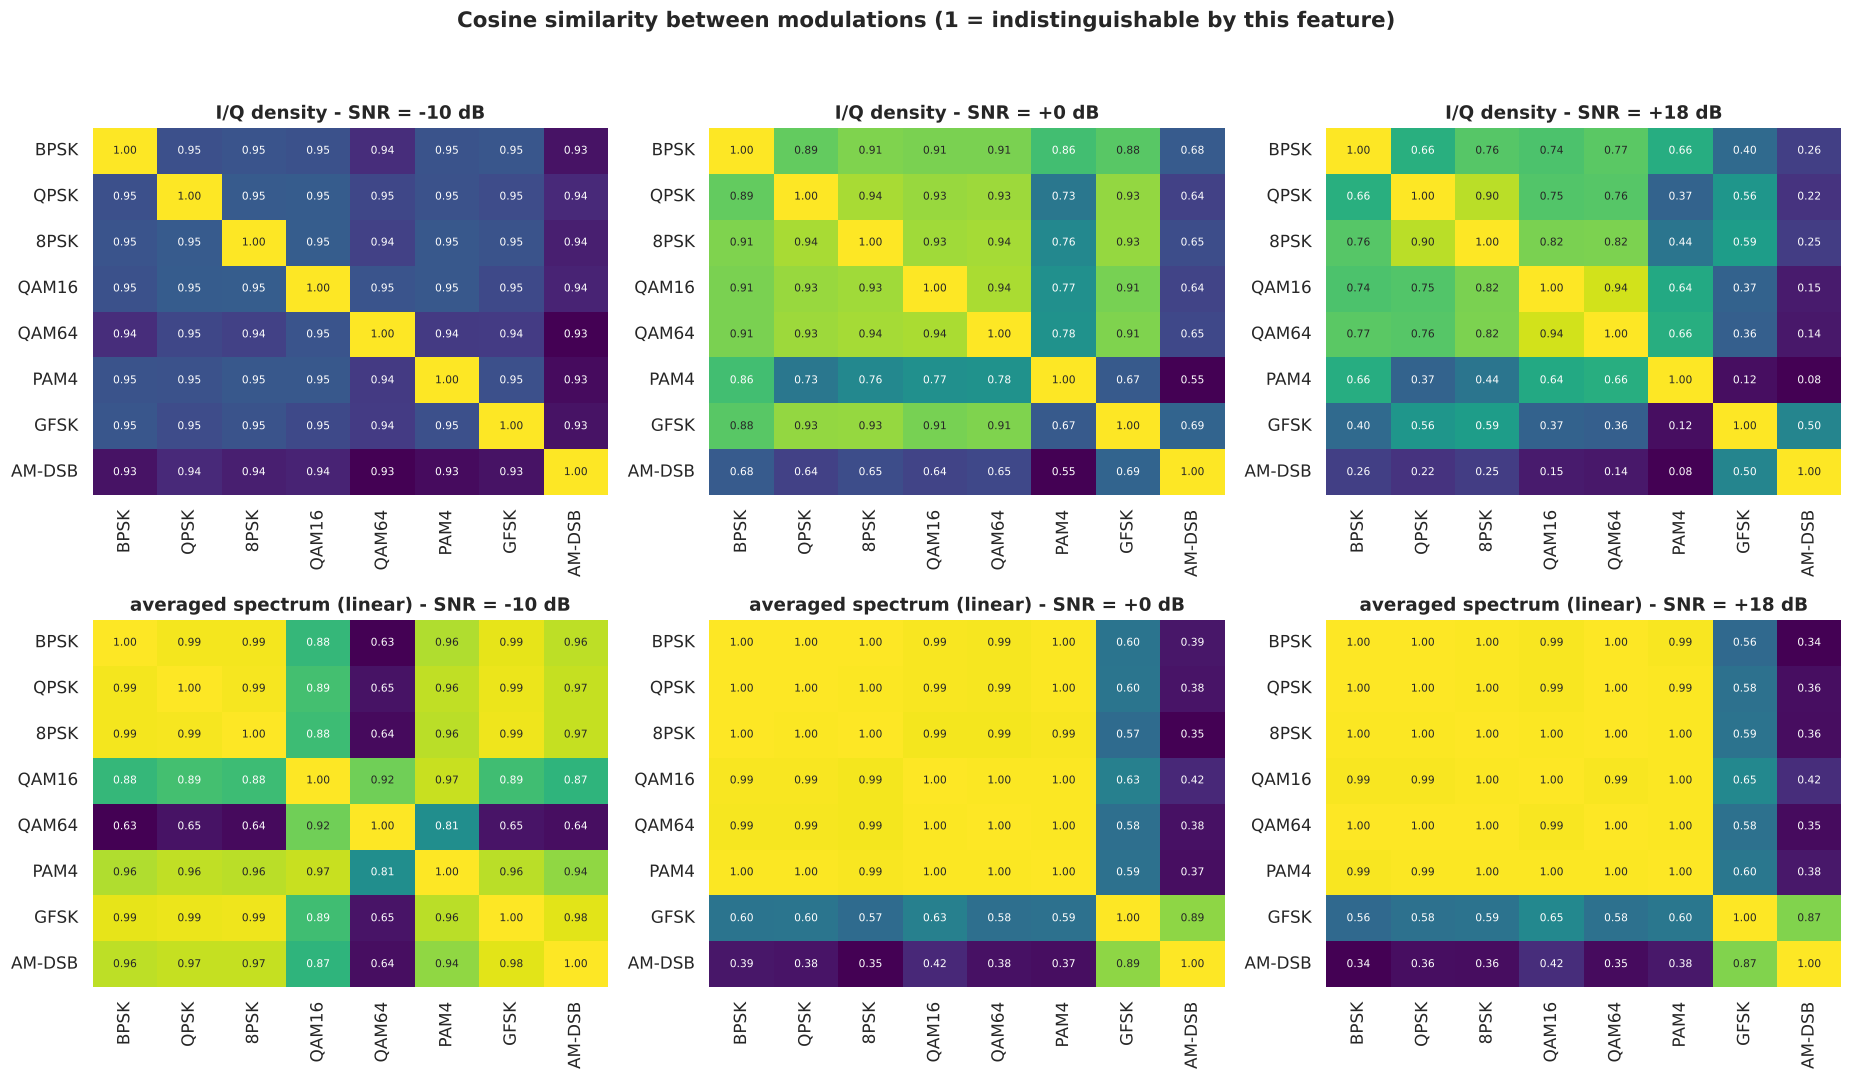

Feature,SNR (dB),Most similar pair,Cosine,Mean off-diagonal
I/Q density,-10.000,8PSK / QAM16,0.951,0.945
I/Q density,0.000,QAM16 / QAM64,0.942,0.817
I/Q density,18.000,QAM16 / QAM64,0.936,0.524
averaged spectrum (linear),-10.000,QPSK / 8PSK,0.995,0.890
averaged spectrum (linear),0.000,BPSK / QPSK,0.998,0.773
averaged spectrum (linear),18.000,QPSK / QAM64,0.999,0.770


In [25]:
def cos_sim(A):
    A = np.asarray(A, float); A = A / np.linalg.norm(A, axis=1, keepdims=True)
    return A @ A.T

sim_snrs = [-10, 0, 18]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
rows = {"I/Q density": lambda m, s: DENS[(m, s)].ravel(),
        "averaged spectrum (linear)": lambda m, s: 10 ** (spec_avg_db(m, s) / 10)}
SIM = {}
for r, (name, fn) in enumerate(rows.items()):
    for c, s in enumerate(sim_snrs):
        M = cos_sim([fn(m, s) for m in SEL_MODS]); SIM[(name, s)] = M
        off = M[~np.eye(len(M), dtype=bool)]
        sns.heatmap(pd.DataFrame(M, index=SEL_MODS, columns=SEL_MODS), annot=True, fmt=".2f", annot_kws={"size": 7},
                    cmap="viridis", vmin=off.min(), vmax=1, cbar=False, ax=axes[r, c])
        axes[r, c].set_title(f"{name} - SNR = {s:+d} dB")
fig.suptitle("Cosine similarity between modulations (1 = indistinguishable by this feature)", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95]); fig.savefig(FIG_DIR / "task2_similarity.png"); plt.show()

# most similar pair of DIFFERENT modulations for each feature / SNR
pairs = []
for (name, s), M in SIM.items():
    M2 = M.copy(); np.fill_diagonal(M2, -1); a, b = np.unravel_index(M2.argmax(), M2.shape)
    pairs.append({"Feature": name, "SNR (dB)": s, "Most similar pair": f"{SEL_MODS[a]} / {SEL_MODS[b]}", "Cosine": M2[a, b],
                  "Mean off-diagonal": M[~np.eye(len(M), dtype=bool)].mean()})
show(pd.DataFrame(pairs), "Most similar pair of modulations", fmt="{:.3f}", hide_index=True)

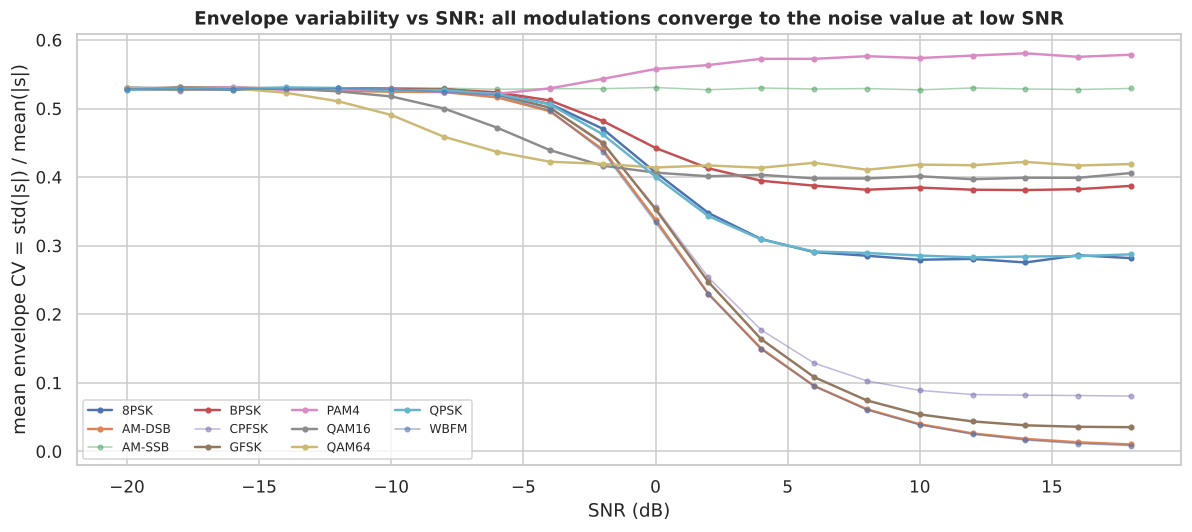

Modulation,-10,0,10,18
BPSK,0.529,0.442,0.385,0.387
QPSK,0.527,0.401,0.286,0.287
8PSK,0.529,0.407,0.279,0.282
QAM16,0.518,0.406,0.401,0.406
QAM64,0.491,0.414,0.418,0.419
PAM4,0.528,0.558,0.574,0.578
GFSK,0.527,0.353,0.054,0.035
AM-DSB,0.525,0.338,0.040,0.010


In [26]:
# Envelope variability CV = std(|s|)/mean(|s|) per frame, averaged over the 1,000 frames of each (modulation, SNR)
cv = pd.DataFrame(index=snrs, columns=mods, dtype=float)
for m in mods:
    for s in snrs:
        a = np.abs(cplx(Xd[(m, s)])); cv.loc[s, m] = float(np.mean(a.std(axis=1) / a.mean(axis=1)))

fig, ax = plt.subplots(figsize=(11, 5))
for m in mods:
    ax.plot(snrs, cv[m], marker="o", ms=3, lw=1.6 if m in SEL_MODS else 1, alpha=1 if m in SEL_MODS else .5, label=m)
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("mean envelope CV = std(|s|) / mean(|s|)")
ax.set_title("Envelope variability vs SNR: all modulations converge to the noise value at low SNR")
ax.legend(ncol=4, fontsize=8); plt.tight_layout(); fig.savefig(FIG_DIR / "task2_envelope_cv_vs_snr.png"); plt.show()
show(cv.loc[VIS_SNRS, SEL_MODS].T.reset_index().rename(columns={"index": "Modulation"}), "Envelope CV at the four visualisation SNRs", fmt="{:.3f}", hide_index=True)

## B.6 Answers to the Task 2 questions

#### 1. Why does a constellation become more dispersed at low SNR?
The receiver sees $s_{rx}[n]=s[n]+w[n]$, where the noise $w[n]=w_I[n]+jw_Q[n]$ is independent on I and Q with variance $\sigma^2=P_s/10^{\mathrm{SNR_{dB}}/10}$. At +18 dB the noise amplitude is ≈ 1/8 of the signal amplitude, so the structure of the signal dominates; at 0 dB both have the same power; at −10 dB the noise power is 10× the signal power (noise radius ≈ 3× the signal radius), so the points form a Gaussian cloud around the origin and the signal structure is buried.
This is visible in the figures: the single-frame trajectories (B.3) dissolve into a cloud at −10 dB, the density maps become the same round blob for every modulation (mean off-diagonal cosine similarity 0.94), and the envelope CV of all modulations converges to ≈ 0.52, the Rayleigh value of pure noise (B.5).

#### 2. Which modulations appear easiest or hardest to distinguish visually?
* **Easiest:** **GFSK** (constant envelope: a clean ring in the density map, CV = 0.035 at +18 dB, two-level instantaneous frequency, narrow spectral peak), **AM-DSB** (almost a single point in the I/Q plane, CV = 0.010, a line at DC) and the **real-valued modulations BPSK/PAM4**, whose points within one frame collapse on a line through the origin instead of filling the plane (the line's angle changes from frame to frame because of the unknown channel phase).
* **Hardest:** **QAM16 vs QAM64** (density cosine 0.94 even at +18 dB) and **QPSK vs 8PSK** (0.90 at +18 dB). At +10/+18 dB the 64 states of QAM64 merge into a filled disc with a bright centre, so the denser the constellation, the harder it is to recognise.

#### 3. Can two modulation types have similar-looking constellations at low SNR?
Yes. At −10 dB **all** pairs are nearly indistinguishable: the I/Q-density cosine similarity is between 0.93 and 0.95 for every pair, including PSK against analog AM-DSB (0.93–0.94). At 0 dB the PSK/QAM family is still strongly similar (0.89–0.94 inside the family) while at +18 dB the mean off-diagonal similarity falls to 0.52. The envelope CV also shows that at −10 dB the eight modulations are within 0.49–0.53.

#### 4. What information can be observed in the time and frequency domains?
* **Time domain:** the symbol timing (BPSK/PAM4 dips of the envelope towards 0 at the symbol transitions, with spikes of instantaneous frequency), the amplitude fluctuation (QAM, PAM4), the **constant envelope** of GFSK/AM-DSB, and the two frequency levels of GFSK. The noise hides all of this below ≈ 0 dB.
* **Frequency domain:** the occupied bandwidth (≈ ±0.08 cycles/sample for the linear digital modulations, so the signal is oversampled), the shape of the pulse-shaping filter, and the **noise floor**, which rises as the SNR decreases. For GFSK and AM-DSB the floor falls from ≈ −44 dB (+10 dB) to ≈ −60 dB (+18 dB); for BPSK, QPSK, 8PSK, QAM16, QAM64 and PAM4 the floor stays near −40 dB between +10 and +18 dB, which suggests a floor set by something other than the additive noise (e.g. pulse-shaping sidelobes or channel impairments). I did not investigate this further.
* **Limit of the spectrum alone:** BPSK, QPSK, 8PSK, QAM16, QAM64 and PAM4 have almost the same averaged spectrum (cosine similarity ≥ 0.99 at 0 and +18 dB, B.5), because they share the same symbol rate and pulse shaping. The spectrum separates only GFSK and AM-DSB from the others (similarity ≈ 0.35–0.65 with the linear modulations). Modulation order is carried by the **amplitude/phase distribution**, i.e. by the I/Q plane, which is why the classifiers take raw I/Q.

## B.7 Summary and limitations
* Noise erases the constellation structure at low SNR: below ≈ 0 dB the modulations are visually indistinguishable, which anticipates the accuracy collapse expected in Task 3.
* Constant-envelope modulations (GFSK, AM-DSB) are the easiest, dense linear modulations (QAM16/64, QPSK/8PSK) the hardest.
* The I/Q constellations of this dataset are **not** ideal point clouds even at +18 dB (rings and loops instead of discrete points). This is consistent with oversampled, pulse-shaped signals and the channel impairments listed in A.11 (fading, LO drift, sample-rate offset). A classifier therefore cannot rely on textbook constellation points.
* Limitations: single-frame plots depend on the chosen frame (we used the median-CV frame and checked with 200-frame averages); the cosine similarities are descriptive measures, not a distinguishability bound; the SNR label of the dataset is taken as given and was not re-estimated.

---
**Next:** Part C — Task 3 (data preparation, leakage-free split and VT-CNN2 baseline).